# Invoice OCR — dữ liệu trong folder hiện tại

Workflow: **ảnh hóa đơn → tiền xử lý/phối cảnh → PAN phát hiện và cắt vùng chữ → VietOCR → sửa lỗi văn bản → PhoBERT phân loại SELLER, ADDRESS, TIMESTAMP, TOTAL_COST → lưu kết quả**.

Notebook đọc `train_images/train_images`, `val_images/val_images`, `mcocr_train_df.csv` và `mcocr_val_sample_df.csv` nằm cạnh notebook. Cấu trúc ảnh trực tiếp trong `train_images` hoặc `val_images` cũng được hỗ trợ.

Chạy các ô từ trên xuống. Đổi `IMAGE_SPLIT` và `IMAGE_NAME` ở ô đầu để chọn ảnh; đặt `IMAGE_NAME = None` để dùng ảnh đầu tiên của tập đã chọn. Kết quả được lưu trong `output/`. CSV validation là dữ liệu mẫu, không mặc định được xem là nhãn đầy đủ để chấm chất lượng.

Ảnh và CSV luôn được đọc cục bộ. Trọng số/cấu hình mô hình được chuẩn bị ở mục riêng; lần đầu cần kết nối mạng nếu các file chưa có trong `weights/`, `configs/`, `heuristic/`.


In [3]:
import os
import zipfile
from pathlib import Path

# Folder containing this notebook and the extracted local dataset.
# Replace Path.cwd() with Path(r"your/folder") if the kernel starts elsewhere.
START_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in (START_DIR, *START_DIR.parents)
     if (folder / "invoice-ocr-with-metrics.ipynb").is_file()
     and (folder / "train_images").is_dir()
     and (folder / "val_images").is_dir()), None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Khong tim thay folder chua notebook, train_images va val_images. "
        "Mo kernel tai folder notebook hoac sua START_DIR o tren."
    )
DATA_DIR = PROJECT_DIR
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def local_image_dir(name):
    for folder in (DATA_DIR / name / name, DATA_DIR / name):
        if folder.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS for p in folder.iterdir()
        ):
            return folder
    raise FileNotFoundError(f"Khong tim thay anh trong {DATA_DIR / name}")

TRAIN_IMAGE_DIR = local_image_dir("train_images")
VAL_IMAGE_DIR = local_image_dir("val_images")
TRAIN_CSV = DATA_DIR / "mcocr_train_df.csv"
VAL_CSV = DATA_DIR / "mcocr_val_sample_df.csv"
WEIGHTS_DIR = PROJECT_DIR / "weights"
CONFIG_DIR = PROJECT_DIR / "configs"
HEURISTIC_DIR = PROJECT_DIR / "heuristic"
CACHE_DIR = str(PROJECT_DIR / "temp")
OUTPUT_DIR = str(PROJECT_DIR / "output")
for folder in (WEIGHTS_DIR, CONFIG_DIR / "detection", CONFIG_DIR / "ocr" / "models",
               HEURISTIC_DIR, Path(CACHE_DIR), Path(OUTPUT_DIR)):
    folder.mkdir(parents=True, exist_ok=True)

# Select a local image. Use IMAGE_NAME=None to select the first image in the split.
IMAGE_SPLIT = "val"  # "train" or "val"
IMAGE_NAME = "mcocr_val_145114gpkup.jpg"
# Downloads below concern model assets only; image/CSV data are always local.
DOWNLOAD_MODEL_ASSETS = True

print("Folder du an:", PROJECT_DIR)
print("Anh train:", TRAIN_IMAGE_DIR)
print("Anh validation:", VAL_IMAGE_DIR)
print("Ket qua:", OUTPUT_DIR)

Folder du an: C:\Users\trinh\OneDrive\Desktop\archive (1)
Anh train: C:\Users\trinh\OneDrive\Desktop\archive (1)\train_images\train_images
Anh validation: C:\Users\trinh\OneDrive\Desktop\archive (1)\val_images\val_images
Ket qua: C:\Users\trinh\OneDrive\Desktop\archive (1)\output


In [4]:
import csv

def read_local_csv(path):
    if not path.is_file():
        raise FileNotFoundError(f"Khong tim thay CSV cuc bo: {path}")
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if "img_id" not in (reader.fieldnames or []):
            raise ValueError(f"CSV thieu cot img_id: {path}")
        return list(reader)

def image_files(folder):
    return sorted(p for p in folder.iterdir()
                  if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

train_images = image_files(TRAIN_IMAGE_DIR)
val_images = image_files(VAL_IMAGE_DIR)
train_rows = read_local_csv(TRAIN_CSV)
val_rows = read_local_csv(VAL_CSV)
for split, images, rows, csv_path in (
    ("train", train_images, train_rows, TRAIN_CSV),
    ("val", val_images, val_rows, VAL_CSV),
):
    names = {image.name for image in images}
    missing = sorted({row["img_id"] for row in rows} - names)
    if missing:
        raise FileNotFoundError(f"{split}: anh trong CSV bi thieu: {missing[:5]}")
    print(f"{split}: {len(images)} anh, {len(rows)} dong CSV ({csv_path.name})")

train: 1155 anh, 1155 dong CSV (mcocr_train_df.csv)
val: 391 anh, 391 dong CSV (mcocr_val_sample_df.csv)


In [5]:
%pip install gdown pylsd-nova

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\trinh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
# Import the necessary packages
import numpy as np
import cv2
from scipy.spatial import distance as dist
from matplotlib.patches import Polygon
import numpy as np
import matplotlib.pyplot as plt
import itertools
import math
import pylsd as lsd
import argparse

# Preprocessing

### Trọng số và cấu hình mô hình
Ba link trọng số trong notebook ban đầu hiện trả về HTTP 404. Notebook dùng các checkpoint công khai PAN (SROIE19), VietOCR (MCOCR) và PhoBERT (MCOCR) từ [dự án nguồn](https://github.com/kaylode/vietnamese-ocr-toolbox#pretrained-weights). Đây là checkpoint thay thế, không khẳng định giống hệt các file ở link cũ.

`model_assets.py` lưu từng checkpoint vào đúng tên file trong `weights/`, tải cấu hình/từ điển từ một commit cố định của repo nguồn và dùng lại file cục bộ sau khi kiểm tra. Không cần tải `Archive.zip`. File tải dở hoặc trang HTML báo lỗi không được coi là trọng số hợp lệ.

Đặt `DOWNLOAD_MODEL_ASSETS = False` khi các tài nguyên đã có đầy đủ. Nếu thiếu file hoặc tải lỗi, ô này liệt kê từng file, đường dẫn đích và link để tải thủ công. Ảnh và CSV luôn được đọc từ folder dữ liệu cục bộ.

In [7]:
# Public model assets from the original Vietnamese OCR Toolbox project.
# The three original private weight links returned HTTP 404.
import importlib
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
import model_assets
importlib.reload(model_assets)
from model_assets import ensure_asset, prepare_model_assets, CONFIG_BASE_URL

weight_url = {
    "pan_resnet18_default": "1GKs-NnezTc6WN0P_Zw7h6wYzRRZdJFKl" ,
    "pan_resnet18_sroie19": "1-Nj8TSM_eqZDZzRArZjWPcVCtl1l2uQP" ,
    "transformerocr_mcocr": "1qpXp_-digz2HPTGY_GPdwstzGLhjC_ot",
    "transformerocr_default_vgg": "13327Y1tz1ohsm5YZMyXVMPIOjoOA0OaA",
    "transformerocr_default_resnet50": "12dTOZ9VP7ZVzwQgVvqBWz5JO5RXXW5NY",
    "transformerocr_default_resnet50_fpn": "12dTOZ9VP7ZVzwQgVvqBWz5JO5RXXW5NY",
    "transformerocr_config": "1xQqR9swWNCTLEa0ensPDT0HDBHTke3xT",
    "phobert_mcocr": "1v4GQPg4Jx5FWvqJ-2k9YCxEd6iFdlXXa"
}

def download_weights(id_or_url, cached=None, md5=None, quiet=False):
    if cached is None:
        import hashlib
        cached = WEIGHTS_DIR / (hashlib.sha256(id_or_url.encode()).hexdigest()[:16] + ".pth")
    return str(ensure_asset(
        id_or_url, cached, kind="torch", allow_download=DOWNLOAD_MODEL_ASSETS, md5=md5
    ))

def download_pretrained_weights(name, cached=None):
    return download_weights(weight_url[name], cached)

model_asset_paths = prepare_model_assets(PROJECT_DIR, allow_download=DOWNLOAD_MODEL_ASSETS)

Model assets ready: 12/12. Local dataset unchanged.


In [8]:

def translate(image, x, y):
	# Define the translation matrix and perform the translation
	M = np.float32([[1, 0, x], [0, 1, y]])
	shifted = cv2.warpAffine(image, M, (image.shape[1], image.shape[0]))

	# Return the translated image
	return shifted

def rotate(image, angle, center = None, scale = 1.0):
	# Grab the dimensions of the image
	(h, w) = image.shape[:2]

	# If the center is None, initialize it as the center of
	# the image
	if center is None:
		center = (w / 2, h / 2)

	# Perform the rotation
	M = cv2.getRotationMatrix2D(center, angle, scale)
	rotated = cv2.warpAffine(image, M, (w, h))

	# Return the rotated image
	return rotated

def resize(image, width = None, height = None, inter = cv2.INTER_AREA):
	# initialize the dimensions of the image to be resized and
	# grab the image size
	dim = None
	(h, w) = image.shape[:2]

	# if both the width and height are None, then return the
	# original image
	if width is None and height is None:
		return image

	# check to see if the width is None
	if width is None:
		# calculate the ratio of the height and construct the
		# dimensions
		r = height / float(h)
		dim = (int(w * r), height)

	# otherwise, the height is None
	else:
		# calculate the ratio of the width and construct the
		# dimensions
		r = width / float(w)
		dim = (width, int(h * r))

	# resize the image
	resized = cv2.resize(image, dim, interpolation = inter)

	# return the resized image
	return resized

## Find contours

In [9]:
def order_points(pts):
    # sort the points based on their x-coordinates
    xSorted = pts[np.argsort(pts[:, 0]), :]

    # grab the left-most and right-most points from the sorted
    # x-roodinate points
    leftMost = xSorted[:2, :]
    rightMost = xSorted[2:, :]

    # now, sort the left-most coordinates according to their
    # y-coordinates so we can grab the top-left and bottom-left
    # points, respectively
    leftMost = leftMost[np.argsort(leftMost[:, 1]), :]
    (tl, bl) = leftMost

    # now that we have the top-left coordinate, use it as an
    # anchor to calculate the Euclidean distance between the
    # top-left and right-most points; by the Pythagorean
    # theorem, the point with the largest distance will be
    # our bottom-right point
    D = dist.cdist(tl[np.newaxis], rightMost, "euclidean")[0]
    (br, tr) = rightMost[np.argsort(D)[::-1], :]

    # return the coordinates in top-left, top-right,
    # bottom-right, and bottom-left order
    return np.array([tl, tr, br, bl], dtype = "float32")
def four_point_transform(image, pts):
    # obtain a consistent order of the points and unpack them
    # individually
    rect = order_points(pts)
    (tl, tr, br, bl) = rect

    # compute the width of the new image, which will be the
    # maximum distance between bottom-right and bottom-left
    # x-coordiates or the top-right and top-left x-coordinates
    widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    maxWidth = max(int(widthA), int(widthB))

    # compute the height of the new image, which will be the
    # maximum distance between the top-right and bottom-right
    # y-coordinates or the top-left and bottom-left y-coordinates
    heightA = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    heightB = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    maxHeight = max(int(heightA), int(heightB))

    # now that we have the dimensions of the new image, construct
    # the set of destination points to obtain a "birds eye view",
    # (i.e. top-down view) of the image, again specifying points
    # in the top-left, top-right, bottom-right, and bottom-left
    # order
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]], dtype = "float32")

    # compute the perspective transform matrix and then apply it
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    # return the warped image
    return warped


## Extract invoice

In [10]:

class DocScanner(object):
    """An image scanner"""

    def __init__(self, interactive=False, MIN_QUAD_AREA_RATIO=0.25, MAX_QUAD_ANGLE_RANGE=40):
        """
        Args:
            interactive (boolean): If True, user can adjust screen contour before
                transformation occurs in interactive pyplot window.
            MIN_QUAD_AREA_RATIO (float): A contour will be rejected if its corners
                do not form a quadrilateral that covers at least MIN_QUAD_AREA_RATIO
                of the original image. Defaults to 0.25.
            MAX_QUAD_ANGLE_RANGE (int):  A contour will also be rejected if the range
                of its interior angles exceeds MAX_QUAD_ANGLE_RANGE. Defaults to 40.
        """
        self.interactive = interactive
        self.MIN_QUAD_AREA_RATIO = MIN_QUAD_AREA_RATIO
        self.MAX_QUAD_ANGLE_RANGE = MAX_QUAD_ANGLE_RANGE

    def filter_corners(self, corners, min_dist=20):
        """Filters corners that are within min_dist of others"""
        def predicate(representatives, corner):
            return all(dist.euclidean(representative, corner) >= min_dist
                       for representative in representatives)

        filtered_corners = []
        for c in corners:
            if predicate(filtered_corners, c):
                filtered_corners.append(c)
        return filtered_corners

    def angle_between_vectors_degrees(self, u, v):
        """Returns the angle between two vectors in degrees"""
        return np.degrees(
            math.acos(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))))

    def get_angle(self, p1, p2, p3):
        """
        Returns the angle between the line segment from p2 to p1
        and the line segment from p2 to p3 in degrees
        """
        a = np.radians(np.array(p1))
        b = np.radians(np.array(p2))
        c = np.radians(np.array(p3))

        avec = a - b
        cvec = c - b

        return self.angle_between_vectors_degrees(avec, cvec)

    def angle_range(self, quad):
        """
        Returns the range between max and min interior angles of quadrilateral.
        The input quadrilateral must be a numpy array with vertices ordered clockwise
        starting with the top left vertex.
        """
        tl, tr, br, bl = quad
        ura = self.get_angle(tl[0], tr[0], br[0])
        ula = self.get_angle(bl[0], tl[0], tr[0])
        lra = self.get_angle(tr[0], br[0], bl[0])
        lla = self.get_angle(br[0], bl[0], tl[0])

        angles = [ura, ula, lra, lla]
        return np.ptp(angles)

    def get_corners(self, img):
        """
        Returns a list of corners ((x, y) tuples) found in the input image. With proper
        pre-processing and filtering, it should output at most 10 potential corners.
        This is a utility function used by get_contours. The input image is expected
        to be rescaled and Canny filtered prior to be passed in.
        """
        lines = lsd.lsd(img)

        # massages the output from LSD
        # LSD operates on edges. One "line" has 2 edges, and so we need to combine the edges back into lines
        # 1. separate out the lines into horizontal and vertical lines.
        # 2. Draw the horizontal lines back onto a canvas, but slightly thicker and longer.
        # 3. Run connected-components on the new canvas
        # 4. Get the bounding box for each component, and the bounding box is final line.
        # 5. The ends of each line is a corner
        # 6. Repeat for vertical lines
        # 7. Draw all the final lines onto another canvas. Where the lines overlap are also corners

        corners = []
        if lines is not None:
            # separate out the horizontal and vertical lines, and draw them back onto separate canvases
            lines = lines.squeeze().astype(np.int32).tolist()
            horizontal_lines_canvas = np.zeros(img.shape, dtype=np.uint8)
            vertical_lines_canvas = np.zeros(img.shape, dtype=np.uint8)
            for line in lines:
                x1, y1, x2, y2, _ = line
                if abs(x2 - x1) > abs(y2 - y1):
                    (x1, y1), (x2, y2) = sorted(((x1, y1), (x2, y2)), key=lambda pt: pt[0])
                    cv2.line(horizontal_lines_canvas, (max(x1 - 5, 0), y1), (min(x2 + 5, img.shape[1] - 1), y2), 255, 2)
                else:
                    (x1, y1), (x2, y2) = sorted(((x1, y1), (x2, y2)), key=lambda pt: pt[1])
                    cv2.line(vertical_lines_canvas, (x1, max(y1 - 5, 0)), (x2, min(y2 + 5, img.shape[0] - 1)), 255, 2)

            lines = []

            # find the horizontal lines (connected-components -> bounding boxes -> final lines)
            (contours, hierarchy) = cv2.findContours(horizontal_lines_canvas, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            contours = sorted(contours, key=lambda c: cv2.arcLength(c, True), reverse=True)[:2]
            horizontal_lines_canvas = np.zeros(img.shape, dtype=np.uint8)
            for contour in contours:
                contour = contour.reshape((contour.shape[0], contour.shape[2]))
                min_x = np.amin(contour[:, 0], axis=0) + 2
                max_x = np.amax(contour[:, 0], axis=0) - 2
                left_y = int(np.average(contour[contour[:, 0] == min_x][:, 1]))
                right_y = int(np.average(contour[contour[:, 0] == max_x][:, 1]))
                lines.append((min_x, left_y, max_x, right_y))
                cv2.line(horizontal_lines_canvas, (min_x, left_y), (max_x, right_y), 1, 1)
                corners.append((min_x, left_y))
                corners.append((max_x, right_y))

            # find the vertical lines (connected-components -> bounding boxes -> final lines)
            (contours, hierarchy) = cv2.findContours(vertical_lines_canvas, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            contours = sorted(contours, key=lambda c: cv2.arcLength(c, True), reverse=True)[:2]
            vertical_lines_canvas = np.zeros(img.shape, dtype=np.uint8)
            for contour in contours:
                contour = contour.reshape((contour.shape[0], contour.shape[2]))
                min_y = np.amin(contour[:, 1], axis=0) + 2
                max_y = np.amax(contour[:, 1], axis=0) - 2
                top_x = int(np.average(contour[contour[:, 1] == min_y][:, 0]))
                bottom_x = int(np.average(contour[contour[:, 1] == max_y][:, 0]))
                lines.append((top_x, min_y, bottom_x, max_y))
                cv2.line(vertical_lines_canvas, (top_x, min_y), (bottom_x, max_y), 1, 1)
                corners.append((top_x, min_y))
                corners.append((bottom_x, max_y))

            # find the corners
            corners_y, corners_x = np.where(horizontal_lines_canvas + vertical_lines_canvas == 2)
            corners += zip(corners_x, corners_y)

        # remove corners in close proximity
        corners = self.filter_corners(corners)
        return corners

    def is_valid_contour(self, cnt, IM_WIDTH, IM_HEIGHT):
        """Returns True if the contour satisfies all requirements set at instantitation"""

        return (len(cnt) == 4 and cv2.contourArea(cnt) > IM_WIDTH * IM_HEIGHT * self.MIN_QUAD_AREA_RATIO
            and self.angle_range(cnt) < self.MAX_QUAD_ANGLE_RANGE)


    def get_contour(self, rescaled_image):
        """
        Returns a numpy array of shape (4, 2) containing the vertices of the four corners
        of the document in the image. It considers the corners returned from get_corners()
        and uses heuristics to choose the four corners that most likely represent
        the corners of the document. If no corners were found, or the four corners represent
        a quadrilateral that is too small or convex, it returns the original four corners.
        """

        # these constants are carefully chosen
        MORPH = 9
        CANNY = 84
        HOUGH = 25

        IM_HEIGHT, IM_WIDTH, _ = rescaled_image.shape

        # convert the image to grayscale and blur it slightly
        gray = cv2.cvtColor(rescaled_image, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (7,7), 0)

        # dilate helps to remove potential holes between edge segments
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT,(MORPH,MORPH))
        dilated = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, kernel)

        # find edges and mark them in the output map using the Canny algorithm
        edged = cv2.Canny(dilated, 0, CANNY)
        test_corners = self.get_corners(edged)
        print("test conters: ", end ='')
        print(test_corners)
        approx_contours = []

        if len(test_corners) >= 4:
            quads = []

            for quad in itertools.combinations(test_corners, 4):
                points = np.array(quad)
                points = order_points(points)
                points = np.array([[p] for p in points], dtype = "int32")
                quads.append(points)

            # get top five quadrilaterals by area
            quads = sorted(quads, key=cv2.contourArea, reverse=True)[:5]
            # sort candidate quadrilaterals by their angle range, which helps remove outliers
            quads = sorted(quads, key=self.angle_range)

            approx = quads[0]
            if self.is_valid_contour(approx, IM_WIDTH, IM_HEIGHT):
                approx_contours.append(approx)

            # for debugging: uncomment the code below to draw the corners and countour found
            # by get_corners() and overlay it on the image

            # cv2.drawContours(rescaled_image, [approx], -1, (20, 20, 255), 2)
            # plt.scatter(*zip(*test_corners))
            # plt.imshow(rescaled_image)
            # plt.show()

        # also attempt to find contours directly from the edged image, which occasionally
        # produces better results
        (cnts, hierarchy) = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:5]

        # loop over the contours
        for c in cnts:
            # approximate the contour
            approx = cv2.approxPolyDP(c, 80, True)
            if self.is_valid_contour(approx, IM_WIDTH, IM_HEIGHT):
                approx_contours.append(approx)
                break

        # If we did not find any valid contours, just use the whole image
        if not approx_contours:
            TOP_RIGHT = (IM_WIDTH, 0)
            BOTTOM_RIGHT = (IM_WIDTH, IM_HEIGHT)
            BOTTOM_LEFT = (0, IM_HEIGHT)
            TOP_LEFT = (0, 0)
            screenCnt = np.array([[TOP_RIGHT], [BOTTOM_RIGHT], [BOTTOM_LEFT], [TOP_LEFT]])
        else:
            screenCnt = max(approx_contours, key=cv2.contourArea)

        return screenCnt.reshape(4, 2)

    def scan(self, image_path):

        RESCALED_HEIGHT = 500.0
        output_dir = OUTPUT_DIR

        # load the image and compute the ratio of the old height
        # to the new height, clone it, and resize it
        image = cv2.imread(str(image_path))

        assert(image is not None)

        ratio = image.shape[0] / RESCALED_HEIGHT
        orig = image.copy()
        rescaled_image = resize(image, int(RESCALED_HEIGHT), int(RESCALED_HEIGHT))

        # get the contour of the document
        screenCnt = self.get_contour(rescaled_image)

        # if self.interactive:
        #     screenCnt = self.interactive_get_contour(screenCnt, rescaled_image)

        # apply the perspective transformation
        warped = four_point_transform(orig, screenCnt * ratio)

        # convert the warped image to grayscale
        gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)

        # sharpen image
        sharpen = cv2.GaussianBlur(gray, (0,0), 3)
        sharpen = cv2.addWeighted(gray, 1.5, sharpen, -0.5, 0)

        # apply adaptive threshold to get black and white effect
        thresh = cv2.adaptiveThreshold(sharpen, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 15)

        # save the transformed image
        basename = os.path.basename(image_path)

        os.makedirs(output_dir, exist_ok=True)
        cv2.imwrite(os.path.join(output_dir, basename), thresh)
        
        # Display images using Matplotlib
        titles = ['Original Image', 'Gray Image', 'Sharpened Image', 'Final Threshold Image']
        images = [image, gray, sharpen, thresh]

        plt.figure(figsize=(10, 8))

        for i in range(4):
            plt.subplot(2, 2, i + 1)
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB), cmap='gray')
            plt.title(titles[i])
            plt.axis('off')

        plt.tight_layout()
        plt.show()


Anh dau vao: C:\Users\trinh\OneDrive\Desktop\archive (1)\val_images\val_images\mcocr_val_145114gpkup.jpg
Co ban ghi CSV: True
test conters: [(2, 607), (188, 591), (387, 579), (47, 134), (27, 587), (436, 352), (452, 569)]


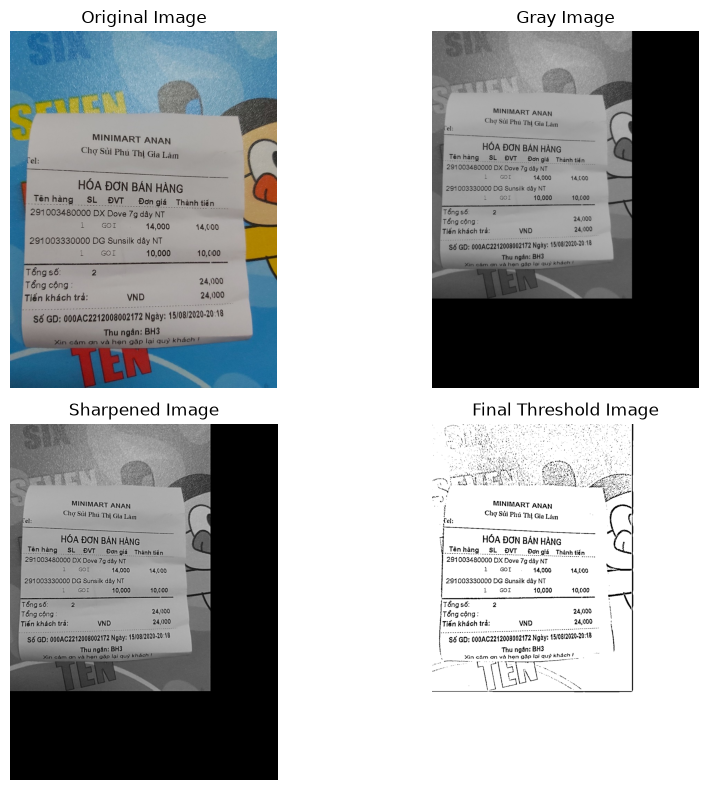

In [11]:
# Select the input directly from the local train/validation dataset.
if IMAGE_SPLIT not in {"train", "val"}:
    raise ValueError("IMAGE_SPLIT phai la 'train' hoac 'val'.")
selected_images = train_images if IMAGE_SPLIT == "train" else val_images
selected_dir = TRAIN_IMAGE_DIR if IMAGE_SPLIT == "train" else VAL_IMAGE_DIR
if not selected_images:
    raise FileNotFoundError(f"Khong co anh trong {selected_dir}")
INPUT_IMAGE = selected_images[0] if IMAGE_NAME is None else selected_dir / IMAGE_NAME
if not INPUT_IMAGE.is_file():
    raise FileNotFoundError(
        f"Khong tim thay anh: {INPUT_IMAGE}. Sua IMAGE_NAME o o dau "
        "hoac dat IMAGE_NAME=None de chon anh dau tien."
    )
img_id = INPUT_IMAGE.stem
selected_rows = train_rows if IMAGE_SPLIT == "train" else val_rows
image_metadata = next((row for row in selected_rows if row["img_id"] == INPUT_IMAGE.name), None)
print("Anh dau vao:", INPUT_IMAGE)
print("Co ban ghi CSV:", image_metadata is not None)

DocScanner(MIN_QUAD_AREA_RATIO=0.1).scan(str(INPUT_IMAGE))

# Text dectection

## Show image functions

In [12]:
def show_img(imgs: np.ndarray, color=False):
    if (len(imgs.shape) == 3 and color) or (len(imgs.shape) == 2 and not color):
        imgs = np.expand_dims(imgs, axis=0)
    for img in imgs:
        plt.figure()
        plt.imshow(img, cmap=None if color else 'gray')


def draw_bbox(img_path, result, color=(255, 0, 0), thickness=2):
    if isinstance(img_path, str):
        img_path = cv2.imread(img_path)
        # img_path = cv2.cvtColor(img_path, cv2.COLOR_BGR2RGB)
    img_path = img_path.copy()
    for point in result:
        point = point.astype(int)
        cv2.line(img_path, tuple(point[0]), tuple(point[1]), color, thickness)
        cv2.line(img_path, tuple(point[1]), tuple(point[2]), color, thickness)
        cv2.line(img_path, tuple(point[2]), tuple(point[3]), color, thickness)
        cv2.line(img_path, tuple(point[3]), tuple(point[0]), color, thickness)
    return img_path

In [13]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.hub import load_state_dict_from_url
import torchvision.transforms as tf
import argparse
import time
import json
import matplotlib.pyplot as plt

In [14]:

def order_points_clockwise(pts):
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect

def sort_box(boxes):
    sorted_boxes = []
    for box in boxes:
        sorted_boxes.append(order_points_clockwise(box))
    mid_points = []
    for box in sorted_boxes:
        try:
            mid = line_intersection((box[0],box[2]), (box[1], box[3]))
            mid_points.append(mid)
        except:
            continue
    sorted_indices = np.argsort(mid_points, axis=0)
    sorted_boxes = sorted(sorted_boxes , key=lambda sorted_indices: [sorted_indices[0][1], sorted_indices[0][0]])
    return sorted_boxes

def line_intersection(line1, line2):
    xdiff = (line1[0][0] - line1[1][0], line2[0][0] - line2[1][0])
    ydiff = (line1[0][1] - line1[1][1], line2[0][1] - line2[1][1])

    def det(a, b):
        return a[0] * b[1] - a[1] * b[0]

    div = det(xdiff, ydiff)
    if div == 0:
       raise Exception('lines do not intersect')

    d = (det(*line1), det(*line2))
    x = det(d, xdiff) / div
    y = det(d, ydiff) / div
    return x, y

def crop_box(img, boxes, out_folder, sort=True):
    h,w,c = img.shape

    if sort:
        boxes = sort_box(boxes)

    for i, box in enumerate(boxes):
        box_name = os.path.join(out_folder, f"{i}.png")

        (x1,y1),(x2,y2),(x3,y3),(x4,y4) = box
        x1,y1,x2,y2,x3,y3,x4,y4 = int(x1),int(y1),int(x2),int(y2),int(x3),int(y3),int(x4),int(y4)
        x1 = max(0, x1)
        x2 = max(0, x2)
        x3 = max(0, x3)
        x4 = max(0, x4)
        y1 = max(0, y1)
        y2 = max(0, y2)
        y3 = max(0, y3)
        y4 = max(0, y4)
        min_x = max(0, min(x1,x2,x3,x4))
        min_y = max(0, min(y1,y2,y3,y4))
        max_x = min(w, max(x1,x2,x3,x4))
        max_y = min(h, max(y1,y2,y3,y4))

        tw = int(np.sqrt((x1-x2)**2 + (y1-y2)**2))
        th = int(np.sqrt((x1-x4)**2 + (y1-y4)**2))
        pt1 = np.float32([(x1,y1),(x2,y2),(x3,y3),(x4,y4)])
        pt2 = np.float32([[0, 0],
                            [tw - 1, 0],
                            [tw - 1, th - 1],
                            [0, th - 1]])
        matrix = cv2.getPerspectiveTransform(pt1,pt2)
        cropped = cv2.warpPerspective(img, matrix, (tw, th))

        try:
            cv2.imwrite(box_name, cropped)
        except:
            print(box_name, " is missing")

    return boxes

## Pixel Agreation Network (PAN)

### RestNet

In [15]:
__all__ = ['ResNet', 'resnet18', 'resnet34', 'resnet50', 'resnet101',
           'resnet152', 'resnext50_32x4d', 'resnext101_32x8d']

model_urls = {
    'resnet18': 'https://download.pytorch.org/models/resnet18-5c106cde.pth',
    'resnet34': 'https://download.pytorch.org/models/resnet34-333f7ec4.pth',
    'resnet50': 'https://download.pytorch.org/models/resnet50-19c8e357.pth',
    'resnet101': 'https://download.pytorch.org/models/resnet101-5d3b4d8f.pth',
    'resnet152': 'https://download.pytorch.org/models/resnet152-b121ed2d.pth',
    'resnext50_32x4d': 'https://download.pytorch.org/models/resnext50_32x4d-7cdf4587.pth',
    'resnext101_32x8d': 'https://download.pytorch.org/models/resnext101_32x8d-8ba56ff5.pth',
}


def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    """3x3 convolution with padding"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)


def conv1x1(in_planes, out_planes, stride=1):
    """1x1 convolution"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None, groups=1,
                 base_width=64, dilation=1, norm_layer=None):
        super(BasicBlock, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError('BasicBlock only supports groups=1 and base_width=64')
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1, downsample=None, groups=1,
                 base_width=64, dilation=1, norm_layer=None):
        super(Bottleneck, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        width = int(planes * (base_width / 64.)) * groups
        # Both self.conv2 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv1x1(inplanes, width)
        self.bn1 = norm_layer(width)
        self.conv2 = conv3x3(width, width, stride, groups, dilation)
        self.bn2 = norm_layer(width)
        self.conv3 = conv1x1(width, planes * self.expansion)
        self.bn3 = norm_layer(planes * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


class ResNet(nn.Module):

    def __init__(self, block, layers, zero_init_residual=False,
                 groups=1, width_per_group=64, replace_stride_with_dilation=None,
                 norm_layer=None):
        super(ResNet, self).__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError("replace_stride_with_dilation should be None "
                             "or a 3-element tuple, got {}".format(replace_stride_with_dilation))
        self.groups = groups
        self.base_width = width_per_group
        self.conv1 = nn.Conv2d(3, self.inplanes, kernel_size=7, stride=2, padding=3,
                               bias=False)
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2,
                                       dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2,
                                       dilate=replace_stride_with_dilation[1])
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2,
                                       dilate=replace_stride_with_dilation[2])

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, Bottleneck):
                    nn.init.constant_(m.bn3.weight, 0)
                elif isinstance(m, BasicBlock):
                    nn.init.constant_(m.bn2.weight, 0)

    def _make_layer(self, block, planes, blocks, stride=1, dilate=False):
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample, self.groups,
                            self.base_width, previous_dilation, norm_layer))
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation,
                                norm_layer=norm_layer))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)

        return c2, c3, c4, c5


def _resnet(arch, block, layers, pretrained, progress, **kwargs):
    model = ResNet(block, layers, **kwargs)
    if pretrained:
        state_dict = load_state_dict_from_url(model_urls[arch],
                                              progress=progress)
        model.load_state_dict(state_dict, strict=False)
        print('load pretrained models from imagenet')
    return model


def resnet18(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNet-18 model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet18', BasicBlock, [2, 2, 2, 2], pretrained, progress,
                   **kwargs)


def resnet34(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNet-34 model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet34', BasicBlock, [3, 4, 6, 3], pretrained, progress,
                   **kwargs)


def resnet50(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNet-50 model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet50', Bottleneck, [3, 4, 6, 3], pretrained, progress,
                   **kwargs)


def resnet101(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNet-101 model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet101', Bottleneck, [3, 4, 23, 3], pretrained, progress,
                   **kwargs)


def resnet152(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNet-152 model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    return _resnet('resnet152', Bottleneck, [3, 8, 36, 3], pretrained, progress,
                   **kwargs)


def resnext50_32x4d(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNeXt-50 32x4d model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['groups'] = 32
    kwargs['width_per_group'] = 4
    return _resnet('resnext50_32x4d', Bottleneck, [3, 4, 6, 3],
                   pretrained, progress, **kwargs)


def resnext101_32x8d(pretrained=False, progress=True, **kwargs):
    """Constructs a ResNeXt-101 32x8d model.

    Args:
        pretrained (bool): If True, returns a model pre-trained on ImageNet
        progress (bool): If True, displays a progress bar of the download to stderr
    """
    kwargs['groups'] = 32
    kwargs['width_per_group'] = 8
    return _resnet('resnext101_32x8d', Bottleneck, [3, 4, 23, 3],
                   pretrained, progress, **kwargs)


### Image segmentation tasks
A complex network architecture for image segmentation tasks. They make use of advanced techniques like feature pyramid networks, feature enhancement, and feature fusion for better performance
- **Feature Pyramid Network (FPN)**: Has several convolutional layers that reduce the dimensionality of the input and smooth the features
- **Feature Pyramid Enhancement Module (FPEM)**: Has several separable convolutional layers that are used to enhance the feature map
- **Feature Pyramid Enhancement Module (FPEM) and Feature Fusion Module (FFM)**:
Takes the number of output channels from the backbone network as input. The forward method defines how the input data is processed through the network. It uses the FPEM class to enhance the feature maps and then fuses them using the FFM.
- **SeparableConv2d**: Defines a separable convolutional layer, which is a more efficient version of a regular convolutional layer. It consists of a depthwise convolution followed by a pointwise convolution. The forward method defines how the input data is processed through the layer

In [16]:
class FPN(nn.Module):
    def __init__(self, backbone_out_channels, **kwargs):
        """
        :param backbone_out_channels: 基础网络输出的维度
        :param kwargs:
        """
        super().__init__()
        result_num = kwargs.get('result_num', 6)
        inplace = True
        conv_out = 256
        # reduce layers
        self.reduce_conv_c2 = nn.Sequential(
            nn.Conv2d(backbone_out_channels[0], conv_out, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        self.reduce_conv_c3 = nn.Sequential(
            nn.Conv2d(backbone_out_channels[1], conv_out, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        self.reduce_conv_c4 = nn.Sequential(
            nn.Conv2d(backbone_out_channels[2], conv_out, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )

        self.reduce_conv_c5 = nn.Sequential(
            nn.Conv2d(backbone_out_channels[3], conv_out, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        # Smooth layers
        self.smooth_p4 = nn.Sequential(
            nn.Conv2d(conv_out, conv_out, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        self.smooth_p3 = nn.Sequential(
            nn.Conv2d(conv_out, conv_out, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        self.smooth_p2 = nn.Sequential(
            nn.Conv2d(conv_out, conv_out, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )

        self.conv = nn.Sequential(
            nn.Conv2d(conv_out * 4, conv_out, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU(inplace=inplace)
        )
        self.out_conv = nn.Conv2d(conv_out, result_num, kernel_size=1, stride=1)

    def forward(self, x):
        c2, c3, c4, c5 = x
        # Top-down
        p5 = self.reduce_conv_c5(c5)
        p4 = self._upsample_add(p5, self.reduce_conv_c4(c4))
        p4 = self.smooth_p4(p4)
        p3 = self._upsample_add(p4, self.reduce_conv_c3(c3))
        p3 = self.smooth_p3(p3)
        p2 = self._upsample_add(p3, self.reduce_conv_c2(c2))
        p2 = self.smooth_p2(p2)

        x = self._upsample_cat(p2, p3, p4, p5)
        x = self.conv(x)
        x = self.out_conv(x)
        return x

    def _upsample_add(self, x, y):
        return F.interpolate(x, size=y.size()[2:], mode='bilinear') + y

    def _upsample_cat(self, p2, p3, p4, p5):
        h, w = p2.size()[2:]
        p3 = F.interpolate(p3, size=(h, w), mode='bilinear')
        p4 = F.interpolate(p4, size=(h, w), mode='bilinear')
        p5 = F.interpolate(p5, size=(h, w), mode='bilinear')
        return torch.cat([p2, p3, p4, p5], dim=1)


class FPEM_FFM(nn.Module):
    def __init__(self, backbone_out_channels, **kwargs):
        """
        PANnet
        :param backbone_out_channels: 基础网络输出的维度
        """
        super().__init__()
        fpem_repeat = kwargs.get('fpem_repeat', 2)
        conv_out = 128
        # reduce layers
        self.reduce_conv_c2 = nn.Sequential(
            nn.Conv2d(in_channels=backbone_out_channels[0], out_channels=conv_out, kernel_size=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU()
        )
        self.reduce_conv_c3 = nn.Sequential(
            nn.Conv2d(in_channels=backbone_out_channels[1], out_channels=conv_out, kernel_size=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU()
        )
        self.reduce_conv_c4 = nn.Sequential(
            nn.Conv2d(in_channels=backbone_out_channels[2], out_channels=conv_out, kernel_size=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU()
        )
        self.reduce_conv_c5 = nn.Sequential(
            nn.Conv2d(in_channels=backbone_out_channels[3], out_channels=conv_out, kernel_size=1),
            nn.BatchNorm2d(conv_out),
            nn.ReLU()
        )
        self.fpems = nn.ModuleList()
        for i in range(fpem_repeat):
            self.fpems.append(FPEM(conv_out))
        self.out_conv = nn.Conv2d(in_channels=conv_out * 4, out_channels=6, kernel_size=1)

    def forward(self, x):
        c2, c3, c4, c5 = x
        # reduce channel
        c2 = self.reduce_conv_c2(c2)
        c3 = self.reduce_conv_c3(c3)
        c4 = self.reduce_conv_c4(c4)
        c5 = self.reduce_conv_c5(c5)

        # FPEM
        for i, fpem in enumerate(self.fpems):
            c2, c3, c4, c5 = fpem(c2, c3, c4, c5)
            if i == 0:
                c2_ffm = c2
                c3_ffm = c3
                c4_ffm = c4
                c5_ffm = c5
            else:
                c2_ffm += c2
                c3_ffm += c3
                c4_ffm += c4
                c5_ffm += c5

        # FFM
        c5 = F.interpolate(c5_ffm, c2_ffm.size()[-2:], mode='bilinear')
        c4 = F.interpolate(c4_ffm, c2_ffm.size()[-2:], mode='bilinear')
        c3 = F.interpolate(c3_ffm, c2_ffm.size()[-2:], mode='bilinear')
        Fy = torch.cat([c2_ffm, c3, c4, c5], dim=1)
        y = self.out_conv(Fy)
        return y


class FPEM(nn.Module):
    def __init__(self, in_channels=128):
        super().__init__()
        self.up_add1 = SeparableConv2d(in_channels, in_channels, 1)
        self.up_add2 = SeparableConv2d(in_channels, in_channels, 1)
        self.up_add3 = SeparableConv2d(in_channels, in_channels, 1)
        self.down_add1 = SeparableConv2d(in_channels, in_channels, 2)
        self.down_add2 = SeparableConv2d(in_channels, in_channels, 2)
        self.down_add3 = SeparableConv2d(in_channels, in_channels, 2)

    def forward(self, c2, c3, c4, c5):
        # up阶段
        c4 = self.up_add1(self._upsample_add(c5, c4))
        c3 = self.up_add2(self._upsample_add(c4, c3))
        c2 = self.up_add3(self._upsample_add(c3, c2))

        # down 阶段
        c3 = self.down_add1(self._upsample_add(c3, c2))
        c4 = self.down_add2(self._upsample_add(c4, c3))
        c5 = self.down_add3(self._upsample_add(c5, c4))
        return c2, c3, c4, c5

    def _upsample_add(self, x, y):
        return F.interpolate(x, size=y.size()[2:], mode='bilinear') + y


class SeparableConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(SeparableConv2d, self).__init__()

        self.depthwise_conv = nn.Conv2d(in_channels=in_channels, out_channels=in_channels, kernel_size=3, padding=1,
                                        stride=stride, groups=in_channels)
        self.pointwise_conv = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.depthwise_conv(x)
        x = self.pointwise_conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x


In [18]:
%pip install pyclipper

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\trinh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [19]:
def decode_clip(preds, scale=1, threshold=0.7311, min_area=5):
    import pyclipper
    import numpy as np
    preds[:2, :, :] = torch.sigmoid(preds[:2, :, :])
    preds = preds.detach().cpu().numpy()
    text = preds[0] > threshold  # text
    kernel = (preds[1] > threshold) * text  # kernel

    label_num, label = cv2.connectedComponents(kernel.astype(np.uint8), connectivity=4)
    bbox_list = []
    for label_idx in range(1, label_num):
        points = np.array(np.where(label == label_idx)).transpose((1, 0))[:, ::-1]
        if points.shape[0] < min_area:
            continue
        rect = cv2.minAreaRect(points)
        poly = cv2.boxPoints(rect).astype(int)

        d_i = cv2.contourArea(poly) * 1.5 / cv2.arcLength(poly, True)
        pco = pyclipper.PyclipperOffset()
        pco.AddPath(poly, pyclipper.JT_ROUND, pyclipper.ET_CLOSEDPOLYGON)
        shrinked_poly = np.array(pco.Execute(d_i))
        if shrinked_poly.size == 0:
            continue
        rect = cv2.minAreaRect(shrinked_poly)
        shrinked_poly = cv2.boxPoints(rect).astype(int)
        if cv2.contourArea(shrinked_poly) < 800 / (scale * scale):
            continue

        bbox_list.append([shrinked_poly[1], shrinked_poly[2], shrinked_poly[3], shrinked_poly[0]])
    return label, np.array(bbox_list)
backbone_dict = {'resnet18': {'models': resnet18, 'out': [64, 128, 256, 512]},
                 'resnet34': {'models': resnet34, 'out': [64, 128, 256, 512]},
                 'resnet50': {'models': resnet50, 'out': [256, 512, 1024, 2048]},
                 'resnet101': {'models': resnet101, 'out': [256, 512, 1024, 2048]},
                 'resnet152': {'models': resnet152, 'out': [256, 512, 1024, 2048]},
                 'resnext50_32x4d': {'models': resnext50_32x4d, 'out': [256, 512, 1024, 2048]},
                 'resnext101_32x8d': {'models': resnext101_32x8d, 'out': [256, 512, 1024, 2048]}
                 }

segmentation_head_dict = {'FPN': FPN, 'FPEM_FFM': FPEM_FFM}
class Model(nn.Module):
    def __init__(self, model_config: dict):
        """
        PANnet
        :param model_config: 模型配置
        """
        super().__init__()
        backbone = model_config['backbone']
        pretrained = model_config['pretrained']
        segmentation_head = model_config['segmentation_head']

        assert backbone in backbone_dict, 'backbone must in: {}'.format(backbone_dict)
        assert segmentation_head in segmentation_head_dict, 'segmentation_head must in: {}'.format(
            segmentation_head_dict)

        backbone_model, backbone_out = backbone_dict[backbone]['models'], backbone_dict[backbone]['out']
        self.backbone = backbone_model(pretrained=pretrained)
        self.segmentation_head = segmentation_head_dict[segmentation_head](backbone_out, **model_config)
        self.name = '{}_{}'.format(backbone, segmentation_head)

    def trainable_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False

    def forward(self, x):
        _, _, H, W = x.size()
        backbone_out = self.backbone(x)
        segmentation_head_out = self.segmentation_head(backbone_out)
        y = F.interpolate(segmentation_head_out, size=(H, W), mode='bilinear', align_corners=True)
        return y


def get_model(config):
    return Model(config)
class PAN:
    def __init__(self, config, model_path=None, state_dict=None):

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        if model_path is not None or state_dict is not None:
            config.model["pretrained"] = False
        self.net = get_model(config.model)
        if model_path is not None:
            checkpoint = torch.load(model_path, map_location=self.device)
            self.net.load_state_dict(checkpoint['state_dict'])
        elif state_dict is not None:
            self.net.load_state_dict(state_dict)

        self.net.to(self.device)
        self.net.eval()

    def predict(self,
            img,
            output_dir:str =None,
            short_size: int = 736,
            crop_region: bool =False):

        """
            Image needs to be in RGB channel
        """

        ori_img = img.copy()
        h, w = ori_img.shape[:2]
        scale = short_size / min(h, w)
        img = cv2.resize(img, None, fx=scale, fy=scale)

        tensor = tf.ToTensor()(img)
        tensor = tensor.unsqueeze_(0)
        tensor = tensor.to(self.device)

        with torch.no_grad():
            if self.device.type == "cuda":
                torch.cuda.synchronize(self.device)
            start = time.time()
            preds = self.net(tensor)[0]
            if self.device.type == "cuda":
                torch.cuda.synchronize(self.device)

            preds, boxes_list = decode_clip(preds)
            scale = (preds.shape[1] / w, preds.shape[0] / h)
            if len(boxes_list):
                boxes_list = boxes_list / scale
            t = time.time() - start

        if crop_region:
            os.makedirs(output_dir, exist_ok=True)
            boxes_list = crop_box(ori_img, boxes_list, output_dir)
        return preds, boxes_list, t

## Implementation

In [20]:
import yaml

class Config():
    def __init__(self, yaml_path):
        with open(yaml_path, encoding="utf-8") as yaml_file:
            self._attr = yaml.load(yaml_file, Loader=yaml.FullLoader)

    def __setattr__(self, name, value):
        self.__dict__[name] = value

    def __getattr__(self, attr):
        try:
            return self._attr[attr]
        except KeyError:
            try:
                return self.__dict__[attr]
            except KeyError:
                return None

    def __str__(self):
        print("##########   CONFIGURATION INFO   ##########")
        pretty(self._attr)
        return '\n'

def pretty(d, indent=0):
  for key, value in d.items():
    print('    ' * indent + str(key) + ':', end='')
    if isinstance(value, dict):
      print()
      pretty(value, indent+1)
    else:
      print('\t' * (indent+1) + str(value))
def init_config(path):
    config = Config(path)
    return config

##########   CONFIGURATION INFO   ##########
project_name:	sroie19
train_imgs:	images/train
val_imgs:	images/val
train_anns:	annotations/train.json
val_anns:	annotations/val.json
pretrained:	./weights/PAN_resnet18_FPEM_FFM.pth
gpu_devices:	0
num_epochs:	100
batch_size:	8
num_workers:	2
image_size:	640
lr_policy:
    name:		adam
    lr:		0.001
    momentum:		0.937
    weight_decay:		0.0005
lr_scheduler:
    name:		step_lr
    step_size:		35
    gamma:		0.1
model:
    backbone:		resnet18
    fpem_repeat:		2
    pretrained:		True
    segmentation_head:		FPEM_FFM
loss:
    alpha:		0.5
    beta:		0.25
    delta_agg:		0.5
    delta_dis:		3
    ohem_ratio:		3




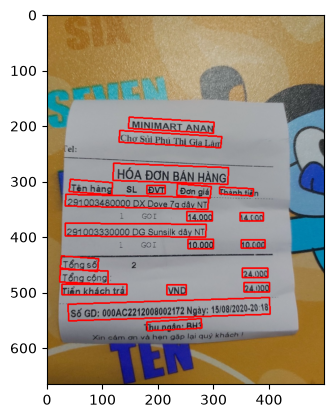

In [21]:
import shutil
weight = str(WEIGHTS_DIR / "PANNet_best_map.pth")
detection_input = str(INPUT_IMAGE)
output = OUTPUT_DIR + os.sep
config = Config(PROJECT_DIR / "configs" / "detection" / "configs.yaml")
class Detection:
    def __init__(self, config_path=None, weight_path=None, model_name=None):
        if config_path is None:
            config_path = str(PROJECT_DIR / "configs" / "detection" / "configs.yaml")
        config = Config(config_path)
        print(config)
        self.model_name = model_name
        # if weight_path is None:
        #     if self.model_name is None:
        #         self.model_name = "pan_resnet18_default"
        #     tmp_path = os.path.join(CACHE_DIR, f'{self.model_name}.pth')
        #     download_pretrained_weights(self.model_name, cached=tmp_path)
        #     weight_path = tmp_path

        self.model = PAN(config, model_path=weight_path)

    def __call__(
        self,
        image_path, # Changed variable name to image_path for clarity
        crop_region=False,
        return_result=False,
        output_path=None):

        """
        Input: path to image
        Output: boxes (coordinates of 4 points)
        """

        if output_path is None:
            assert crop_region, "Please specify output_path"
        else:
            output_path = os.path.join(output_path, "crops", img_id)
            if os.path.exists(output_path):
                shutil.rmtree(output_path)
            os.makedirs(output_path, exist_ok=True)

        # Load the image
        image = cv2.imread(image_path) # Load image here
        image = resize(image, 500, 500)

        # Detect and OCR for final result
        _, boxes_list, _ = self.model.predict(
            image, # Pass the loaded image
            output_path,
            crop_region=crop_region)

        if return_result:
            img = draw_bbox(image, boxes_list)
            img = resize(img, 500, 500)
#             specific_output_path = f"{output_path}/{img_id}"
#             try:
#                 os.makedirs(specific_output_path, exist_ok=True)
#                 print(f"Directory {output_path} created successfully.")
#             except Exception as e:
#                 print(f"An error occurred while creating the directory: {e}")
#         # Save the image
#             try:
#                 cv2.imwrite(f"{specific_output_path}/bonded.jpg", img)
#                 print(f"Image saved successfully at {specific_output_path}.")
#             except Exception as e:
#                 print(f"An error occurred while saving the image: {e}")
            

        if return_result:
            return boxes_list, img
        else:
            return boxes_list
# Detect texts
det_model = Detection(weight_path=weight)
boxes, img2  = det_model(
    detection_input, # Selected local image
    crop_region=True,                               #Crop detected regions for OCR
    return_result=True,                             # Return plotted result
    output_path=OUTPUT_DIR + os.sep  #Path to save cropped regions
)

plt.imshow(img2)
plt.show()

# Text OCR

In [22]:
from torchvision import models
from torch import nn
import math
from PIL import Image
from torch.nn.functional import log_softmax, softmax
from collections import defaultdict
import difflib

In [23]:
import re
def natural_keys(text):
    '''
    alist.sort(key=natural_keys) sorts in human order
    http://nedbatchelder.com/blog/200712/human_sorting.html
    (See Toothy's implementation in the comments)
    '''
    def atoi(text):
        return int(text) if text.isdigit() else text

    return [ atoi(c) for c in re.split(r'(\d+)', text) ]

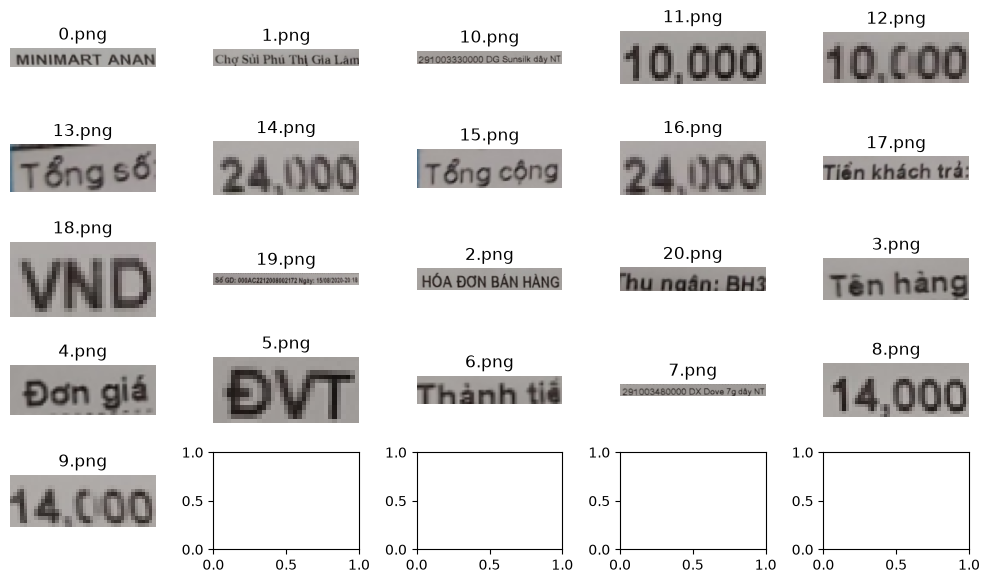

In [24]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Directory path containing images
directory = str(Path(OUTPUT_DIR) / "crops" / img_id)

# Get list of all image files in the directory
image_files = [filename for filename in os.listdir(directory) if filename.endswith('.png') or filename.endswith('.jpg')]

# Define the size of the grid for subplots
num_images = len(image_files)
num_rows = 5  # Number of rows of subplots
num_cols = max(1, (num_images + num_rows - 1) // num_rows)  # Calculate number of columns based on number of images

# Create a figure and axes
fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 6), squeeze=False)

# Iterate over the image files and plot them in subplots
for i, filename in enumerate(image_files):
    row = i // num_cols
    col = i % num_cols
    img_path = os.path.join(directory, filename)
    img = mpimg.imread(img_path)
    axes[row, col].imshow(img)
    axes[row, col].axis('off')  # Turn off axis numbers and ticks
    axes[row, col].set_title(filename)  # Set title as the filename

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

## Utils

In [25]:
def download_config(name):
    aliases = {"resnet_transformer.yml": "resnet-transformer.yml"}
    name = aliases.get(name, name)
    local_path = ensure_asset(
        f"{CONFIG_BASE_URL}/{name}", CONFIG_DIR / "ocr" / "models" / name,
        allow_download=DOWNLOAD_MODEL_ASSETS,
    )
    return yaml.safe_load(local_path.read_text(encoding="utf-8"))

def compute_accuracy(ground_truth, predictions, mode='full_sequence'):
    """
    Computes accuracy
    :param ground_truth:
    :param predictions:
    :param display: Whether to print values to stdout
    :param mode: if 'per_char' is selected then
                 single_label_accuracy = correct_predicted_char_nums_of_single_sample / single_label_char_nums
                 avg_label_accuracy = sum(single_label_accuracy) / label_nums
                 if 'full_sequence' is selected then
                 single_label_accuracy = 1 if the prediction result is exactly the same as label else 0
                 avg_label_accuracy = sum(single_label_accuracy) / label_nums
    :return: avg_label_accuracy
    """
    if mode == 'per_char':

        accuracy = []

        for index, label in enumerate(ground_truth):
            prediction = predictions[index]
            total_count = len(label)
            correct_count = 0
            try:
                for i, tmp in enumerate(label):
                    if tmp == prediction[i]:
                        correct_count += 1
            except IndexError:
                continue
            finally:
                try:
                    accuracy.append(correct_count / total_count)
                except ZeroDivisionError:
                    if len(prediction) == 0:
                        accuracy.append(1)
                    else:
                        accuracy.append(0)
        avg_accuracy = np.mean(np.array(accuracy).astype(np.float32), axis=0)
    elif mode == 'full_sequence':
        try:
            correct_count = 0
            for index, label in enumerate(ground_truth):
                prediction = predictions[index]
                if prediction == label:
                    correct_count += 1
            avg_accuracy = correct_count / len(ground_truth)
        except ZeroDivisionError:
            if not predictions:
                avg_accuracy = 1
            else:
                avg_accuracy = 0
    else:
        raise NotImplementedError('Other accuracy compute mode has not been implemented')

    return avg_accuracy

In [26]:
url_config = {
        'vgg_transformer':'vgg-transformer.yml',
        'resnet_transformer':'resnet_transformer.yml',
        'resnet_fpn_transformer':'resnet_fpn_transformer.yml',
        'vgg_seq2seq':'vgg-seq2seq.yml',
        'vgg_convseq2seq':'vgg_convseq2seq.yml',
        'vgg_decoderseq2seq':'vgg_decoderseq2seq.yml',
        'base':'base.yml',
        }

class Cfg(dict):
    def __init__(self, config_dict):
        super(Cfg, self).__init__(**config_dict)
        self.__dict__ = self

    @staticmethod
    def load_config_from_file(fname):
        base_config = download_config(url_config['base'])

        with open(fname, encoding='utf-8') as f:
            config = yaml.safe_load(f)
        base_config.update(config)

        return Cfg(base_config)

    @staticmethod
    def load_config_from_name(name):
        base_config = download_config(url_config['base'])
        config = download_config(url_config[name])

        base_config.update(config)
        return Cfg(base_config)

    def save(self, fname):
        with open(fname, 'w') as outfile:
            yaml.dump(dict(self), outfile, default_flow_style=False, allow_unicode=True)

class Predictor():
    def __init__(self, config):

        device = config['device']
        
        model, vocab = build_model(config)
        weights = config['weights']

        if config['weights'].startswith('http'):
            weights = download_weights(config['weights'])
        else:
            weights = config['weights']

        model.load_state_dict(torch.load(weights, map_location=torch.device(device)))

        self.config = config
        self.model = model
        self.vocab = vocab
        
    def predict(self, img, return_prob=False):
        img = process_input(img, self.config['dataset']['image_height'], 
                self.config['dataset']['image_min_width'], self.config['dataset']['image_max_width'])        
        img = img.to(self.config['device'])

        if self.config['predictor']['beamsearch']:
            sent = translate_beam_search(img, self.model)
            s = sent
            prob = None
        else:
            s, prob = translate(img, self.model)
            s = s[0].tolist()
            prob = prob[0]

        s = self.vocab.decode(s)
        
        if return_prob:
            return s, prob
        else:
            return s

## Backbone
- cnn
- vgg
- resnet


### Resnet

In [27]:


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock, self).__init__()
        self.conv1 = self._conv3x3(inplanes, planes)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = self._conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride

    def _conv3x3(self, in_planes, out_planes, stride=1):
        "3x3 convolution with padding"
        return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                         padding=1, bias=False)

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)

        return out
    
class ResNet(nn.Module):

    def __init__(self, input_channel, output_channel, block, layers):
        super(ResNet, self).__init__()

        self.output_channel_block = [int(output_channel / 4), int(output_channel / 2), output_channel, output_channel]

        self.inplanes = int(output_channel / 8)
        self.conv0_1 = nn.Conv2d(input_channel, int(output_channel / 16),
                                 kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0_1 = nn.BatchNorm2d(int(output_channel / 16))
        self.conv0_2 = nn.Conv2d(int(output_channel / 16), self.inplanes,
                                 kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0_2 = nn.BatchNorm2d(self.inplanes)
        self.relu = nn.ReLU(inplace=True)

        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.layer1 = self._make_layer(block, self.output_channel_block[0], layers[0])
        self.conv1 = nn.Conv2d(self.output_channel_block[0], self.output_channel_block[
                               0], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(self.output_channel_block[0])

        self.maxpool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.layer2 = self._make_layer(block, self.output_channel_block[1], layers[1], stride=1)
        self.conv2 = nn.Conv2d(self.output_channel_block[1], self.output_channel_block[
                               1], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(self.output_channel_block[1])

        self.maxpool3 = nn.MaxPool2d(kernel_size=2, stride=(2, 1), padding=(0, 1))
        self.layer3 = self._make_layer(block, self.output_channel_block[2], layers[2], stride=1)
        self.conv3 = nn.Conv2d(self.output_channel_block[2], self.output_channel_block[
                               2], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(self.output_channel_block[2])

        self.layer4 = self._make_layer(block, self.output_channel_block[3], layers[3], stride=1)
        self.conv4_1 = nn.Conv2d(self.output_channel_block[3], self.output_channel_block[
                                 3], kernel_size=2, stride=(2, 1), padding=(0, 1), bias=False)
        self.bn4_1 = nn.BatchNorm2d(self.output_channel_block[3])
        self.conv4_2 = nn.Conv2d(self.output_channel_block[3], self.output_channel_block[
                                 3], kernel_size=2, stride=1, padding=0, bias=False)
        self.bn4_2 = nn.BatchNorm2d(self.output_channel_block[3])

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes * block.expansion
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv0_1(x)
        x = self.bn0_1(x)
        x = self.relu(x)
        x = self.conv0_2(x)
        x = self.bn0_2(x)
        x = self.relu(x)

        x = self.maxpool1(x)
        x = self.layer1(x)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.maxpool2(x)
        x = self.layer2(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        x = self.maxpool3(x)
        x = self.layer3(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = self.relu(x)

        x = self.layer4(x)
        x = self.conv4_1(x)
        x = self.bn4_1(x)
        x = self.relu(x)
        x = self.conv4_2(x)
        x = self.bn4_2(x)
        conv = self.relu(x)
        
        conv = conv.transpose(-1, -2)
        conv = conv.flatten(2)
        conv = conv.permute(-1, 0, 1)

        return conv

def Resnet50(ss, hidden):
    return ResNet(3, hidden, BasicBlock, [1, 2, 5, 3])



### Vgg

In [28]:
class Vgg(nn.Module):
    def __init__(self, name, ss, ks, hidden, pretrained=True, dropout=0.5):
        super(Vgg, self).__init__()

        if name == 'vgg11_bn':
            cnn = models.vgg11_bn(pretrained=pretrained)
        elif name == 'vgg19_bn':
            cnn = models.vgg19_bn(pretrained=pretrained)

        pool_idx = 0
        
        for i, layer in enumerate(cnn.features):
            if isinstance(layer, torch.nn.MaxPool2d):        
                cnn.features[i] = torch.nn.AvgPool2d(kernel_size=ks[pool_idx], stride=ss[pool_idx], padding=0)
                pool_idx += 1
 
        self.features = cnn.features
        self.dropout = nn.Dropout(dropout)
        self.last_conv_1x1 = nn.Conv2d(512, hidden, 1)

    def forward(self, x):
        """
        Shape: 
            - x: (N, C, H, W)
            - output: (W, N, C)
        """

        conv = self.features(x)
        conv = self.dropout(conv)
        conv = self.last_conv_1x1(conv)

#        conv = rearrange(conv, 'b d h w -> b d (w h)')
        conv = conv.transpose(-1, -2)
        conv = conv.flatten(2)
        conv = conv.permute(-1, 0, 1)
        return conv

def vgg11_bn(ss, ks, hidden, pretrained=True, dropout=0.5):
    return Vgg('vgg11_bn', ss, ks, hidden, pretrained, dropout)

def vgg19_bn(ss, ks, hidden, pretrained=True, dropout=0.5):
    return Vgg('vgg19_bn', ss, ks, hidden, pretrained, dropout)
   


### CNN
encapsulates a convolutional neural network (CNN) model, allowing for easy switching between different backbone architectures and providing methods to freeze and unfreeze the model's parameters

In [29]:
class CNN(nn.Module):
    def __init__(self, backbone, **kwargs):
        super(CNN, self).__init__()

        if backbone == 'vgg11_bn':
            self.model = vgg11_bn(**kwargs)
        elif backbone == 'vgg19_bn':
            self.model = vgg19_bn(**kwargs)
        elif backbone == 'resnet50':
            self.model = Resnet50(**kwargs)

    def forward(self, x):
        return self.model(x)

    def freeze(self):
        for name, param in self.model.features.named_parameters():
            if name != 'last_conv_1x1':
                param.requires_grad = False

    def unfreeze(self):
        for param in self.model.features.parameters():
            param.requires_grad = True


## Sequence model

In [30]:
class LanguageTransformer(nn.Module):
    def __init__(self, vocab_size, 
                 d_model, nhead, 
                 num_encoder_layers, num_decoder_layers, 
                 dim_feedforward, max_seq_length, 
                 pos_dropout, trans_dropout):
        super().__init__()
        
        self.d_model = d_model
        self.embed_tgt = nn.Embedding(vocab_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, pos_dropout, max_seq_length)
#        self.learned_pos_enc = LearnedPositionalEncoding(d_model, pos_dropout, max_seq_length)

        self.transformer = nn.Transformer(d_model, nhead, 
                                          num_encoder_layers, num_decoder_layers, 
                                          dim_feedforward, trans_dropout)
        
        self.fc = nn.Linear(d_model, vocab_size)
        
    def forward(self, src, tgt, src_key_padding_mask=None, tgt_key_padding_mask=None, memory_key_padding_mask=None):
        """
        Shape:
            - src: (W, N, C)
            - tgt: (T, N) 
            - src_key_padding_mask: (N, S)
            - tgt_key_padding_mask: (N, T)
            - memory_key_padding_mask: (N, S)
            - output: (N, T, E)
            
        """
        tgt_mask = self.gen_nopeek_mask(tgt.shape[0]).to(src.device)
        
        src = self.pos_enc(src*math.sqrt(self.d_model))
#        src = self.learned_pos_enc(src*math.sqrt(self.d_model))

        tgt = self.pos_enc(self.embed_tgt(tgt) * math.sqrt(self.d_model))
        
        output = self.transformer(src, tgt, tgt_mask=tgt_mask, src_key_padding_mask=src_key_padding_mask,
                                  tgt_key_padding_mask=tgt_key_padding_mask, memory_key_padding_mask=memory_key_padding_mask)
#        output = rearrange(output, 't n e -> n t e')
        output = output.transpose(0, 1)
        return self.fc(output)

    def gen_nopeek_mask(self, length):
        mask = (torch.triu(torch.ones(length, length)) == 1).transpose(0, 1)
        mask = mask.float().masked_fill(mask == 0, float('-inf')).masked_fill(mask == 1, float(0.0))

        return mask
    
    def forward_encoder(self, src):
        src = self.pos_enc(src*math.sqrt(self.d_model))
        memory = self.transformer.encoder(src)
        return memory
    
    def forward_decoder(self, tgt, memory):
        tgt_mask = self.gen_nopeek_mask(tgt.shape[0]).to(tgt.device)
        tgt = self.pos_enc(self.embed_tgt(tgt) * math.sqrt(self.d_model))
        
        output = self.transformer.decoder(tgt, memory, tgt_mask=tgt_mask)
#        output = rearrange(output, 't n e -> n t e')
        output = output.transpose(0, 1)

        return self.fc(output), memory
    
    def expand_memory(self, memory, beam_size):
        memory = memory.repeat(1, beam_size, 1)
        return memory
    
    def get_memory(self, memory, i):
        memory = memory[:, [i], :]
        return memory

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=100):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0), :]

        return self.dropout(x)
 
class LearnedPositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=100):
        super(LearnedPositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        self.pos_embed = nn.Embedding(max_len, d_model)
        self.layernorm = LayerNorm(d_model)

    def forward(self, x):
        seq_len = x.size(0)
        pos = torch.arange(seq_len, dtype=torch.long, device=x.device)
        pos = pos.unsqueeze(-1).expand(x.size()[:2])
        x = x + self.pos_embed(pos)
        return self.dropout(self.layernorm(x))

class LayerNorm(nn.Module):
    "A layernorm module in the TF style (epsilon inside the square root)."
    def __init__(self, d_model, variance_epsilon=1e-12):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta  = nn.Parameter(torch.zeros(d_model))
        self.variance_epsilon = variance_epsilon

    def forward(self, x):
        u = x.mean(-1, keepdim=True)
        s = (x - u).pow(2).mean(-1, keepdim=True)
        x = (x - u) / torch.sqrt(s + self.variance_epsilon)
        return self.gamma * x + self.beta  


## VIETOCR

In [31]:
class VietOCR(nn.Module):
    def __init__(self, vocab_size,
                 backbone,
                 cnn_args, 
                 transformer_args, seq_modeling='transformer'):
        
        super(VietOCR, self).__init__()
        
        self.cnn = CNN(backbone, **cnn_args)
        self.seq_modeling = seq_modeling

        if seq_modeling == 'transformer':
            self.transformer = LanguageTransformer(vocab_size, **transformer_args)
        elif seq_modeling == 'seq2seq':
            self.transformer = Seq2Seq(vocab_size, **transformer_args)
        elif seq_modeling == 'convseq2seq':
            self.transformer = ConvSeq2Seq(vocab_size, **transformer_args)
        else:
            raise('Not Support Seq Model')

    def forward(self, img, tgt_input, tgt_key_padding_mask):
        """
        Shape:
            - img: (N, C, H, W)
            - tgt_input: (T, N)
            - tgt_key_padding_mask: (N, T)
            - output: b t v
        """
        src = self.cnn(img)

        if self.seq_modeling == 'transformer':
            outputs = self.transformer(src, tgt_input, tgt_key_padding_mask=tgt_key_padding_mask)
        elif self.seq_modeling == 'seq2seq':
            outputs = self.transformer(src, tgt_input)
        elif self.seq_modeling == 'convseq2seq': 
            outputs = self.transformer(src, tgt_input)
        return outputs



## Beam Algorithm
Used in sequence generation tasks such as machine translation or text summarization. Beam search is a heuristic search algorithm that explores a graph by expanding the most promising nodes in a limited set. It maintains a fixed number of best partial solutions (the "beam") at each step, which helps to balance between breadth-first and depth-first search strategies, aiming to find a more optimal solution more efficiently than exhaustive search.



In [32]:
import torch

class Beam:

    def __init__(self, beam_size=8, min_length=0, n_top=1, ranker=None,
                 start_token_id=1, end_token_id=2):
        self.beam_size = beam_size
        self.min_length = min_length
        self.ranker = ranker

        self.end_token_id = end_token_id
        self.top_sentence_ended = False

        self.prev_ks = []
        self.next_ys = [torch.LongTensor(beam_size).fill_(start_token_id)] # remove padding

        self.current_scores = torch.FloatTensor(beam_size).zero_()
        self.all_scores = []

        # Time and k pair for finished.
        self.finished = []
        self.n_top = n_top

        self.ranker = ranker

    def advance(self, next_log_probs):
        # next_probs : beam_size X vocab_size

        vocabulary_size = next_log_probs.size(1)
        # current_beam_size = next_log_probs.size(0)

        current_length = len(self.next_ys)
        if current_length < self.min_length:
            for beam_index in range(len(next_log_probs)):
                next_log_probs[beam_index][self.end_token_id] = -1e10

        if len(self.prev_ks) > 0:
            beam_scores = next_log_probs + self.current_scores.unsqueeze(1).expand_as(next_log_probs)
            # Don't let EOS have children.
            last_y = self.next_ys[-1]
            for beam_index in range(last_y.size(0)):
                if last_y[beam_index] == self.end_token_id:
                    beam_scores[beam_index] = -1e10 # -1e20 raises error when executing
        else:
            beam_scores = next_log_probs[0]
            
        flat_beam_scores = beam_scores.view(-1)
        top_scores, top_score_ids = flat_beam_scores.topk(k=self.beam_size, dim=0, largest=True, sorted=True)

        self.current_scores = top_scores
        self.all_scores.append(self.current_scores)
        
        prev_k = top_score_ids // vocabulary_size  # (beam_size, )
        next_y = top_score_ids - prev_k * vocabulary_size  # (beam_size, )
                
        
        self.prev_ks.append(prev_k)
        self.next_ys.append(next_y)

        for beam_index, last_token_id in enumerate(next_y):
            
            if last_token_id == self.end_token_id:
                
                # skip scoring
                self.finished.append((self.current_scores[beam_index], len(self.next_ys) - 1, beam_index))

        if next_y[0] == self.end_token_id:
            self.top_sentence_ended = True

    def get_current_state(self):
        "Get the outputs for the current timestep."
        return torch.stack(self.next_ys, dim=1)

    def get_current_origin(self):
        "Get the backpointers for the current timestep."
        return self.prev_ks[-1]

    def done(self):
        return self.top_sentence_ended and len(self.finished) >= self.n_top

    def get_hypothesis(self, timestep, k):
        hypothesis = []
        for j in range(len(self.prev_ks[:timestep]) - 1, -1, -1):
            hypothesis.append(self.next_ys[j + 1][k])
            # for RNN, [:, k, :], and for trnasformer, [k, :, :]
            k = self.prev_ks[j][k]

        return hypothesis[::-1]

    def sort_finished(self, minimum=None):
        if minimum is not None:
            i = 0
            # Add from beam until we have minimum outputs.
            while len(self.finished) < minimum:
                # global_scores = self.global_scorer.score(self, self.scores)
                # s = global_scores[i]
                s = self.current_scores[i]
                self.finished.append((s, len(self.next_ys) - 1, i))
                i += 1

        self.finished = sorted(self.finished, key=lambda a: a[0], reverse=True)
        scores = [sc for sc, _, _ in self.finished]
        ks = [(t, k) for _, t, k in self.finished]
        return scores, ks


## Voba 
Used in natural language processing (NLP) tasks. It provides a way to convert between characters and their corresponding integer indices, along with special tokens for padding, start of sequence, end of sequence, and a mask token

In [33]:
class Vocab():
    def __init__(self, chars):
        self.pad = 0
        self.go = 1
        self.eos = 2
        self.mask_token = 3

        self.chars = chars

        self.c2i = {c:i+4 for i, c in enumerate(chars)}

        self.i2c = {i+4:c for i, c in enumerate(chars)}
        
        self.i2c[0] = '<pad>'
        self.i2c[1] = '<sos>'
        self.i2c[2] = '<eos>'
        self.i2c[3] = '*'

    def encode(self, chars):
        return [self.go] + [self.c2i[c] for c in chars] + [self.eos]
    
    def decode(self, ids):
        first = 1 if self.go in ids else 0
        last = ids.index(self.eos) if self.eos in ids else None
        sent = ''.join([self.i2c[i] for i in ids[first:last]])
        return sent
    
    def __len__(self):
        return len(self.c2i) + 4
    
    def batch_decode(self, arr):
        texts = [self.decode(ids) for ids in arr]
        return texts

    def __str__(self):
        return self.chars


## Processing

In [34]:
def batch_translate_beam_search(img, model, beam_size=4, candidates=1, max_seq_length=128, sos_token=1, eos_token=2):
    # img: NxCxHxW
    model.eval()
    device = img.device
    sents = []

    with torch.no_grad():
        src = model.cnn(img)
        print(src.shap)
        memories = model.transformer.forward_encoder(src)
        for i in range(src.size(0)):
#            memory = memories[:,i,:].repeat(1, beam_size, 1) # TxNxE
            memory = model.transformer.get_memory(memories, i)
            sent = beamsearch(memory, model, device, beam_size, candidates, max_seq_length, sos_token, eos_token)
            sents.append(sent)

    sents = np.asarray(sents)

    return sents
   
def translate_beam_search(img, model, beam_size=4, candidates=1, max_seq_length=128, sos_token=1, eos_token=2):
    # img: 1xCxHxW
    model.eval()
    device = img.device

    with torch.no_grad():
        src = model.cnn(img)
        memory = model.transformer.forward_encoder(src) #TxNxE
        sent = beamsearch(memory, model, device, beam_size, candidates, max_seq_length, sos_token, eos_token)

    return sent
        
def beamsearch(memory, model, device, beam_size=4, candidates=1, max_seq_length=128, sos_token=1, eos_token=2):    
    # memory: Tx1xE
    model.eval()

    beam = Beam(beam_size=beam_size, min_length=0, n_top=candidates, ranker=None, start_token_id=sos_token, end_token_id=eos_token)

    with torch.no_grad():
#        memory = memory.repeat(1, beam_size, 1) # TxNxE
        memory = model.transformer.expand_memory(memory, beam_size)

        for _ in range(max_seq_length):
            
            tgt_inp = beam.get_current_state().transpose(0,1).to(device)  # TxN
            decoder_outputs, memory = model.transformer.forward_decoder(tgt_inp, memory)

            log_prob = log_softmax(decoder_outputs[:,-1, :].squeeze(0), dim=-1)
            beam.advance(log_prob.cpu())
            
            if beam.done():
                break
                
        scores, ks = beam.sort_finished(minimum=1)

        hypothesises = []
        for i, (times, k) in enumerate(ks[:candidates]):
            hypothesis = beam.get_hypothesis(times, k)
            hypothesises.append(hypothesis)
    
    return [1] + [int(i) for i in hypothesises[0][:-1]]

def translate(img, model, max_seq_length=128, sos_token=1, eos_token=2):
    "data: BxCXHxW"
    model.eval()
    device = img.device

    with torch.no_grad():
        src = model.cnn(img)
        memory = model.transformer.forward_encoder(src)

        translated_sentence = [[sos_token]*len(img)]
        char_probs = [[1]*len(img)]

        max_length = 0

        while max_length <= max_seq_length and not all(np.any(np.asarray(translated_sentence).T==eos_token, axis=1)):

            tgt_inp = torch.LongTensor(translated_sentence).to(device)
            
#            output = model(img, tgt_inp, tgt_key_padding_mask=None)
#            output = model.transformer(src, tgt_inp, tgt_key_padding_mask=None)
            output, memory = model.transformer.forward_decoder(tgt_inp, memory)
            output = softmax(output, dim=-1)
            output = output.to('cpu')

            values, indices  = torch.topk(output, 5)
            
            indices = indices[:, -1, 0]
            indices = indices.tolist()
            
            values = values[:, -1, 0]
            values = values.tolist()
            char_probs.append(values)

            translated_sentence.append(indices)   
            max_length += 1

            del output

        translated_sentence = np.asarray(translated_sentence).T
        
        char_probs = np.asarray(char_probs).T
        char_probs = np.multiply(char_probs, translated_sentence>3)
        char_probs = np.sum(char_probs, axis=-1)/(char_probs>0).sum(-1)
    
    return translated_sentence, char_probs


def build_model(config):
    vocab = Vocab(config['vocab'])
    device = config['device']
    
    model = VietOCR(len(vocab),
            config['backbone'],
            config['cnn'], 
            config['transformer'],
            config['seq_modeling'])
    
    model = model.to(device)

    return model, vocab

def resize(w, h, expected_height, image_min_width, image_max_width):
    new_w = int(expected_height * float(w) / float(h))
    round_to = 10
    new_w = math.ceil(new_w/round_to)*round_to
    new_w = max(new_w, image_min_width)
    new_w = min(new_w, image_max_width)

    return new_w, expected_height

def process_image(image, image_height, image_min_width, image_max_width):
    img = image.convert('RGB')

    w, h = img.size
    new_w, image_height = resize(w, h, image_height, image_min_width, image_max_width)

    img = img.resize((new_w, image_height), Image.Resampling.LANCZOS)

    img = np.asarray(img).transpose(2,0, 1)
    img = img/255
    return img

def process_input(image, image_height, image_min_width, image_max_width):
    img = process_image(image, image_height, image_min_width, image_max_width)
    img = img[np.newaxis, ...]
    img = torch.FloatTensor(img)
    return img

def predict(filename, config):
    img = Image.open(filename)
    img = process_input(img)

    img = img.to(config['device'])

    model, vocab = build_model(config)
    s = translate(img, model)[0].tolist()
    s = vocab.decode(s)
    
    return s


In [35]:
class OCR:
    def __init__(self, config_path=None, weight_path=None, model_name=None):
        if config_path is None:
            config_path = str(PROJECT_DIR / "configs" / "ocr" / "configs.yaml")
        config = Config(config_path)
        ocr_config = Cfg.load_config_from_name(config.model_name)
        ocr_config['cnn']['pretrained']=False
        ocr_config['device'] = 'cuda:0' if torch.cuda.is_available() else 'cpu'
        ocr_config['predictor']['beamsearch']=False

        self.model_name = model_name
        if weight_path is None:
            if self.model_name is None:
                self.model_name = "transformerocr_default_vgg"
            tmp_path = os.path.join(CACHE_DIR, f'{self.model_name}.pth')
            download_pretrained_weights(self.model_name, cached=tmp_path)
            weight_path = tmp_path
        ocr_config['weights'] = weight_path
        self.model = Predictor(ocr_config)

    def __call__(self, img, return_prob=False):
        if isinstance(img, np.ndarray):
            img = Image.fromarray(img)
        return self.model.predict(img, return_prob)

    def predict_folder(self, img_paths, return_probs=False):
        texts = []
        if return_probs:
            probs = []
        for i, img_path in enumerate(img_paths):
            img = Image.open(img_path)
            if return_probs:
                text, prob = self(img, True)
                texts.append(text)
                probs.append(prob)
            else:
                text = self(img, False)
                texts.append(text)

        if return_probs:
            return texts, probs
        else:
            return texts

## Predict

In [36]:
ocr_weight = str(WEIGHTS_DIR / "transformerocr.pth")
ocr_model = OCR(weight_path=ocr_weight)

# Text OCR

crop_dir = Path(OUTPUT_DIR) / "crops" / img_id
img_paths=os.listdir(crop_dir) # Cropped regions
img_paths.sort(key=natural_keys)
img_paths = [os.path.join(str(crop_dir), i) for i in img_paths]

texts, probs = ocr_model.predict_folder(img_paths, return_probs=True) # OCR
# texts = correction(texts)   # Word correction

for i in texts:
    print(i)

C:\Users\trinh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\trinh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\trinh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\modules\transformer.py:143: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_

MINIMART ANAN
Chợ Sủi Phú Thị Gia Lâm
HÓA ĐƠN BÁN HÀNG
Tên hàng
Đơn giá
ĐVT
Thành tiến
291003480000 DX Dove 7g dây NT
14,000
14,000
29100333000 DG Sunsilk dây NT
10,000
10,000
Tổng số:
24,000
Tổng cộng
24,000
Tiền khách trả:
VND
Số GD: 000AC2212008002172 Ngày: 15/08/2020-20:18
Thu ngân: BH3A


## Correction
- Based on a given dictionary and a specified mode of operation, either "trie" or "edit distance"
- Implements several heuristic-based text matching and retrieval techniques, leveraging data structures like tries and algorithms such as difflib's sequence matcher and regular expressions. The core components of this script are the TrieNode and Trie classes, which are used to build a prefix tree (trie) for efficient string matching, and the Matcher class, which utilizes the trie for finding similar strings.


In [37]:
import pandas as pd
def trie_correction(texts, dictionary, threshold=0.85):
    preds = []
    match_score = []
    matcher = Matcher(dictionary)
    for query_txt in texts:
        key, score = matcher.get_match(query_txt.lower())
        if score > threshold:
            preds.append(key)
            match_score.append(score)
        else:
            preds.append(query_txt)
            match_score.append(0)
    return preds, match_score

def diff_correction(texts, dictionary, threshold=0.85):
    def sentence_distance(p1,p2):
        return difflib.SequenceMatcher(None, p1, p2).ratio()
    
    preds = []
    match_score = []

    for query_txt in texts:
        dis_list = [(key, sentence_distance(query_txt.lower(), key)) for key in dictionary.keys()]
        dis_list = sorted(dis_list,key=lambda tup: tup[1],reverse=True)[:5]
        key, score = dis_list[0]
        if score > threshold:
            preds.append(key)
            match_score.append(score)
        else:
            preds.append(query_txt)
            match_score.append(0)
    return preds, match_score

def get_heuristic_correction(type_='diff'):
    return trie_correction if type_=='trie' else diff_correction
class Correction:
    def __init__(self, dictionary=None, mode="ed"):
        assert mode in ["trie", "ed"], "Mode is not supported"
        self.mode = mode
        self.dictionary = dictionary

        self.use_trie = False
        self.use_ed = False

        if self.mode == 'trie':
            self.use_trie = True
        if self.mode == 'ed':
            self.use_ed = True
        
        if self.use_ed:
            self.ed = get_heuristic_correction('diff')
        if self.use_trie:
            self.trie = get_heuristic_correction('trie')
        
        if self.use_ed or self.use_trie:
            if self.dictionary is None:
                self.dictionary = {}
                df = pd.read_csv(HEURISTIC_DIR / "custom-dictionary.csv")
                for id, row in df.iterrows():
                    self.dictionary[row.text.lower()] = row.lbl

    def __call__(self, query_texts, return_score=False):
        if self.use_ed:
            preds, score = self.ed(query_texts, self.dictionary)
            
        if self.use_trie:
            preds, score = self.trie(query_texts, self.dictionary)
        
        if return_score:
            return preds, score
        else:
            return preds

In [38]:
correction = Correction()
texts = correction(texts)   # Word correction

for i in texts:
    print(i)

MINIMART ANAN
Chợ Sủi Phú Thị Gia Lâm
HÓA ĐƠN BÁN HÀNG
Tên hàng
Đơn giá
ĐVT
Thành tiến
291003480000 DX Dove 7g dây NT
14,000
14,000
29100333000 DG Sunsilk dây NT
10,000
10,000
Tổng số:
24,000
tổng cộng
24,000
tiền khách trả
VND
Số GD: 000AC2212008002172 Ngày: 15/08/2020-20:18
Thu ngân: BH3A


## Retrieve information

### PhoBERT

In [39]:
%pip install typing_extensions

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\trinh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [40]:
from typing import (
    IO,
    Any,
    BinaryIO,
    ClassVar,
    Generic,
    Mapping,
    MutableMapping,
    MutableSequence,
    NoReturn,
    Protocol,
    Sequence,
    SupportsAbs,
    SupportsBytes,
    SupportsComplex,
    SupportsFloat,
    SupportsIndex,
    TypeVar,
    final,
    overload,
)


In [41]:
from tqdm import tqdm
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import pandas as pd
import numpy as np
import os
import sys
from torch.optim import SGD, Adam, RMSprop, AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau, StepLR
from typing import MutableMapping, Any, Iterable, Tuple, overload, ClassVar, Iterator
import transformers
from string import punctuation

def clean(s):
    res = re.sub(r"(\w)(\()(\w)", "\g<1> \g<2>\g<3>", s)
    res = re.sub(r"\b\d+\b", "", res)
    res = re.sub(r"(\w)([),.:;]+)(\w)", "\g<1>\g<2> \g<3>", res)
    res = re.sub(r"(\w)(\.\()(\w)", "\g<1>. (\g<3>", res)
    res = re.sub(r"\s+", " ", res)
    res = res.strip()
    return res
def stripclean(arr):
    res = [s.strip().strip(punctuation) for s in arr]
    return " ".join([i for i in res if i != ""])

# CACHE_DIR is configured in the first cell.

# Registry to store class references
CLASS_REGISTRY = {}

# Decorator to register classes
def register_class(cls):
    CLASS_REGISTRY[cls.__name__] = cls
    return cls

@register_class
class AutoModelForClassification(nn.Module):
    def __init__(self, pretrained_model=None, num_labels=1, freeze_backbone=False):
        super().__init__()
        # The task checkpoint below supplies all weights; only fetch the small
        # backbone configuration rather than downloading the base model again.
        backbone_config = transformers.AutoConfig.from_pretrained(
            pretrained_model, num_labels=num_labels
        )
        self.model = transformers.AutoModelForSequenceClassification.from_config(backbone_config)
        if freeze_backbone:
            self.freeze()

    def freeze(self):
        for param in self.model.roberta.parameters():
            param.requires_grad = False

    def forward(self, input_ids, attention_mask):
        outputs = self.model(input_ids=input_ids, attention_mask=attention_mask)
        x = outputs.logits
        x = x.squeeze(-1)
        return x

@register_class
class MCOCRDataset(Dataset):
    def __init__(self, pretrained_model, csv_path, is_train, max_len):
        self.csv_path = csv_path
        self.is_train = is_train
        self.max_len = max_len
        self.df = pd.read_csv(self.csv_path)
        self.tokenizer = AutoTokenizer.from_pretrained(pretrained_model)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.loc[index]
        text = str(row.text).lower()
        target = row.lbl if self.is_train else None
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt",
        )

        if self.is_train:
            target = torch.tensor(target, dtype=torch.long)
            return {
                "text": text,
                "input_ids": encoding["input_ids"].flatten(),
                "attention_mask": encoding["attention_mask"].flatten(),
                "target": target,
            }
        else:
            return {
                "text": text,
                "input_ids": encoding["input_ids"].flatten(),
                "attention_mask": encoding["attention_mask"].flatten(),
            }

@register_class
class MCOCRDataset_from_list(MCOCRDataset):
    def __init__(self, ls, pretrained_model, max_len, preproc=False):
        self.is_train = False
        self.max_len = max_len
        self.df = pd.DataFrame.from_dict({"text": ls, "lbl": len(ls) * [0],})
        if preproc:
            self.df["text"] = self.df["text"].apply(clean).str.split().apply(stripclean)
        self.tokenizer = AutoTokenizer.from_pretrained(pretrained_model)

# Function to create instance from config using the registry
def get_instance(config, **kwargs):
    assert "name" in config, "The configuration does not contain 'name'."
    config.setdefault("args", {})
    if config["args"] is None:
        config["args"] = {}

    instance_name = config["name"]
    print("Instance name:", instance_name)
    
    if not isinstance(instance_name, str):
        raise ValueError(f"Expected 'name' to be a string but got {type(instance_name).__name__}: {instance_name}")
    
    if instance_name not in CLASS_REGISTRY:
        raise ValueError(f"'{instance_name}' is not a registered class.")
    
    return CLASS_REGISTRY[instance_name](**config["args"], **kwargs)

def inference(model, dataloader, device):
    model.eval()
    preds = []
    targets = []
    pbar = tqdm(enumerate(dataloader), total=len(dataloader))
    for i, x in pbar:
        input_ids = x["input_ids"].to(device)
        attention_mask = x["attention_mask"].to(device)
        outputs = model(input_ids, attention_mask)
        outputs = F.softmax(outputs, dim=1)
        preds += [(outputs.detach().cpu().numpy())]

    preds = np.concatenate(preds, axis=0)

    return np.argmax(preds, 1), np.max(preds, 1)



class PhoBERT:
    def __init__(self, idx_mapping, weight_path=None):
        self.idx_mapping = idx_mapping
        if weight_path is None:
            tmp_path = str(WEIGHTS_DIR / "bert_weight.pth")
            download_pretrained_weights("phobert_mcocr", tmp_path)
            weight_path = tmp_path
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        meta_data = torch.load(weight_path, map_location="cpu", weights_only=True)
        
        # Print the keys and shapes/types of meta_data contents
#         print("Keys in meta_data:", meta_data.keys())
#         print("Shape of meta_data contents:", {key: (value.shape if isinstance(value, torch.Tensor) else type(value)) for key, value in meta_data.items()})
        
        self.cfg = meta_data["config"]
        # The public MCOCR checkpoint has four output classes, in this order:
        # SELLER, ADDRESS, TIMESTAMP, TOTAL_COST. NONE is reserved by heuristics.
        label_count = self.cfg["model"]["args"]["num_labels"]
        if any(index not in self.idx_mapping for index in range(label_count)):
            raise ValueError(f"Label mapping does not cover {label_count} checkpoint classes")
        model_state = meta_data["model_state_dict"]

        # Debugging output for configuration
#         print("Configuration:", self.cfg)
        
        self.model = get_instance(self.cfg["model"]).to(self.device)

        # Filter out unexpected keys from model_state
        expected_keys = set(self.model.state_dict().keys())
        model_state = {k: v for k, v in model_state.items() if k in expected_keys}

        # Print filtered keys for debugging
#         print("Filtered model state keys:", model_state.keys())
        
        self.model.load_state_dict(model_state)

    def __call__(self, texts):
        dataset = MCOCRDataset_from_list(
            texts,
            pretrained_model=self.cfg["model"]["args"]["pretrained_model"],
            max_len=31,
            preproc=True,
        )

        dataloader = DataLoader(
            dataset=dataset, batch_size=2, shuffle=False, pin_memory=False
        )

        with torch.no_grad():
            preds, probs = inference(
                model=self.model, dataloader=dataloader, device=self.device
            )

        labels = [self.idx_mapping[x] for x in preds]
        return labels, probs

<>:17: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\g'
<>:20: SyntaxWarning: invalid escape sequence '\g'
<>:17: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\g'
<>:20: SyntaxWarning: invalid escape sequence '\g'
C:\Users\trinh\AppData\Local\Temp\ipykernel_31784\544285255.py:17: SyntaxWarning: invalid escape sequence '\g'
  res = re.sub(r"(\w)(\()(\w)", "\g<1> \g<2>\g<3>", s)
C:\Users\trinh\AppData\Local\Temp\ipykernel_31784\544285255.py:19: SyntaxWarning: invalid escape sequence '\g'
  res = re.sub(r"(\w)([),.:;]+)(\w)", "\g<1>\g<2> \g<3>", res)
C:\Users\trinh\AppData\Local\Temp\ipykernel_31784\544285255.py:20: SyntaxWarning: invalid escape sequence '\g'
  res = re.sub(r"(\w)(\.\()(\w)", "\g<1>. (\g<3>", res)


### Diff vs Trie

In [42]:
def get_multiple_trie_match(texts, dictionary):
    preds = []
    probs = []
    matcher = Matcher(dictionary)
    for query_txt in texts:
        key, score = matcher.get_match(query_txt.lower())
        if key is None or score ==0 or math.isnan(score):
            preds.append(4)
            probs.append(0.0)
        else:
            preds.append(dictionary[key])
            probs.append(score/len(key))
    return preds, probs

def get_multiple_diff_match(texts, dictionary):
    def sentence_distance(p1,p2):
        return difflib.SequenceMatcher(None, p1, p2).ratio()
    
    preds = []
    probs = []

    for query_txt in texts:
        dis_list = [(key, sentence_distance(query_txt.lower(), key)) for key in dictionary.keys()]
        dis_list = sorted(dis_list,key=lambda tup: tup[1],reverse=True)[:5]
        key, score = dis_list[0]
        if score != 0 and not math.isnan(score):
            preds.append(dictionary[key])
        else:
            preds.append(4)
        probs.append(score)
    return preds, probs
def regex_timestamp(texts):
    preds = []
    time = r'\d{2}:\d{2}:\d{2}|\d{2}-\d{2}-\d{2}|\d{2}\.\d{2}\.\d{2}'
    date = r'(\d+/\d+/\d+)'
    regex = '|'.join([time,date])
    for query_txt in texts:
        x = re.search(regex, query_txt)
        if x:
            preds.append(1)
        else:
            preds.append(0)
    return preds
def get_heuristic_retrieval(type_='diff'):
    return get_multiple_trie_match if type_=='trie' else get_multiple_diff_match

In [43]:
class Retrieval:
    def __init__(self, class_mapping, dictionary=None, mode="all", bert_weight=None):
        assert mode in ["all", "bert", "trie", "ed"], "Mode is not supported"
        self.mode = mode

        self.dictionary = dictionary
        self.class_mapping = class_mapping
        self.idx_mapping = {v: k for k, v in class_mapping.items()}

        self.use_bert = mode in ['all', 'bert']
        self.use_trie = mode in ['all', 'trie']
        self.use_ed = mode in ['all', 'ed']

        if self.use_bert:
            self.bert = PhoBERT(self.idx_mapping, bert_weight)
#         if self.use_ed:
#             self.ed = get_heuristic_retrieval('diff')
#         if self.use_trie:
#             self.trie = get_heuristic_retrieval('trie')

#         if self.use_ed or self.use_trie:
#             if self.dictionary is None:
#                 self.dictionary = {}
#                 df = pd.read_csv(str(PROJECT_DIR / "heuristic" / "custom-dictionary.csv')
#                 for id, row in df.iterrows():
#                     self.dictionary[row.text.lower()] = row.lbl

    def ensemble(self, df):
        preds = []
        probs = []

        for id, row in df.iterrows():
            if row["timestamp"] == 1:
                preds.append("TIMESTAMP")
                probs.append(5.0)
            elif self.use_ed and self.use_trie and row["bert_labels"] == row["diff_labels"]:
                preds.append(row["bert_labels"])
                probs.append(row["bert_probs"] + row["diff_probs"])
            elif self.use_trie and row["bert_labels"] == row["trie_labels"]:
                preds.append(row["bert_labels"])
                probs.append(row["bert_probs"] + row["trie_probs"])
            elif self.use_ed and self.use_trie and row["trie_labels"] == row["diff_labels"]:
                preds.append(row["trie_labels"])
                probs.append(row["trie_probs"] + row["diff_probs"])
            else:
                if self.use_ed and row.get("diff_probs", 0) >= 0.4:
                    preds.append(row["diff_labels"])
                    probs.append(row["diff_probs"])
                elif self.use_trie and row.get("trie_probs", 0) >= 0.25:
                    preds.append(row["trie_labels"])
                    probs.append(row["trie_probs"])
                else:
                    preds.append(row["bert_labels"])
                    probs.append(row["bert_probs"] / 3)

        return preds, probs

    def __call__(self, query_texts):
        df = pd.DataFrame()
        if self.use_bert:
            preds, probs = self.bert(query_texts)
            df["bert_labels"] = preds
            df["bert_probs"] = probs
#         if self.use_ed:
#             preds, probs = self.ed(query_texts, self.dictionary)
#             df["diff_labels"] = [self.idx_mapping[x] for x in preds]
#             df["diff_probs"] = probs
#         if self.use_trie:
#             preds, probs = self.trie(query_texts, self.dictionary)
#             df["trie_labels"] = [self.idx_mapping[x] for x in preds]
#             df["trie_probs"] = probs

        timestamps = regex_timestamp(query_texts)
        df["timestamp"] = timestamps

        # Ensure the DataFrame has all necessary columns for the ensemble method
        if self.use_ed:
            df["diff_labels"] = df.get("diff_labels", "")
            df["diff_probs"] = df.get("diff_probs", 0.0)
        if self.use_trie:
            df["trie_labels"] = df.get("trie_labels", "")
            df["trie_probs"] = df.get("trie_probs", 0.0)

        preds, probs = self.ensemble(df)
        return preds, probs

In [44]:
# Example usage
class_mapping = {"SELLER":0, "ADDRESS":1, "TIMESTAMP":2, "TOTAL_COST":3, "NONE":4}
idx_mapping = {0:"SELLER", 1:"ADDRESS", 2:"TIMESTAMP", 3:"TOTAL_COST", 4:"NONE"}


retrieval = Retrieval(class_mapping, mode='bert')
preds, probs = retrieval(texts)

Instance name: AutoModelForClassification


100%|██████████| 11/11 [00:00<00:00, 27.45it/s]


In [45]:
preds


['SELLER',
 'ADDRESS',
 'ADDRESS',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'ADDRESS',
 'SELLER',
 'TOTAL_COST',
 'TOTAL_COST',
 'SELLER',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TOTAL_COST',
 'TIMESTAMP',
 'ADDRESS']

In [46]:
probs

[0.33330976963043213,
 0.332994004090627,
 0.1560975213845571,
 0.31506359577178955,
 0.23792201280593872,
 0.1268082857131958,
 0.2159186601638794,
 0.16432987650235495,
 0.32587335507074994,
 0.32587335507074994,
 0.27317025264104206,
 0.32587335507074994,
 0.32587335507074994,
 0.3251311580340068,
 0.32587335507074994,
 0.3290327986081441,
 0.32587335507074994,
 0.33326266209284466,
 0.2610579530398051,
 5.0,
 0.307243009408315]

In [47]:
print(len(probs), len(preds), len(texts))

21 21 21


## Visualization 

In [48]:
import matplotlib
import matplotlib.pyplot as plt
import webcolors
STANDARD_COLORS = [
    'Crimson', 'LawnGreen' , 'DeepSkyBlue', 'Gold', 'DarkGrey', 'BlanchedAlmond', 'Bisque',
    'Aquamarine', 'BlueViolet', 'BurlyWood', 'CadetBlue', 'AntiqueWhite',
    'Chocolate', 'Coral', 'CornflowerBlue', 'Cornsilk', 'Crimson', 'Cyan',
    'DarkCyan', 'DarkGoldenRod', 'Azure', 'DarkKhaki', 'DarkOrange',
    'DarkOrchid', 'DarkSalmon', 'DarkSeaGreen', 'DarkTurquoise', 'DarkViolet',
    'DeepPink', 'DeepSkyBlue', 'DodgerBlue', 'FireBrick', 'FloralWhite',
    'ForestGreen', 'Fuchsia', 'Gainsboro', 'GhostWhite', 'Gold', 'GoldenRod',
    'Salmon', 'Tan', 'HoneyDew', 'HotPink', 'IndianRed', 'Ivory', 'Khaki',
    'Lavender', 'LavenderBlush', 'AliceBlue', 'LemonChiffon', 'LightBlue',
    'LightCoral', 'LightCyan', 'LightGoldenRodYellow', 'LightGray', 'LightGrey',
    'LightGreen', 'LightPink', 'LightSalmon', 'LightSeaGreen', 'LightSkyBlue',
    'LightSlateGray', 'LightSlateGrey', 'LightSteelBlue', 'LightYellow', 'Lime',
    'LimeGreen', 'Linen', 'Magenta', 'MediumAquaMarine', 'MediumOrchid',
    'MediumPurple', 'MediumSeaGreen', 'MediumSlateBlue', 'MediumSpringGreen',
    'MediumTurquoise', 'MediumVioletRed', 'MintCream', 'MistyRose', 'Moccasin',
    'NavajoWhite', 'OldLace', 'Olive', 'OliveDrab', 'Orange', 'OrangeRed',
    'Orchid', 'PaleGoldenRod', 'PaleGreen', 'PaleTurquoise', 'PaleVioletRed',
    'PapayaWhip', 'PeachPuff', 'Peru', 'Pink', 'Plum', 'PowderBlue', 'Purple',
    'Red', 'RosyBrown', 'RoyalBlue', 'SaddleBrown', 'Green', 'SandyBrown',
    'SeaGreen', 'SeaShell', 'Sienna', 'Silver', 'SkyBlue', 'SlateBlue',
    'SlateGray', 'SlateGrey', 'Snow', 'SpringGreen', 'SteelBlue', 'GreenYellow',
    'Teal', 'Thistle', 'Tomato', 'Turquoise', 'Violet', 'Wheat', 'White',
    'WhiteSmoke', 'Yellow', 'YellowGreen'
]

def from_colorname_to_bgr(color):
    rgb_color = webcolors.name_to_rgb(color)
    result = (rgb_color.blue, rgb_color.green, rgb_color.red)
    return result

def standard_to_bgr(list_color_name):
    standard = []
    for i in range(len(list_color_name) - 36):  # -36 used to match the len(obj_list)
        standard.append(from_colorname_to_bgr(list_color_name[i]))
    return standard

color_list = standard_to_bgr(STANDARD_COLORS)
def find_highest_score_each_class(labels, probs, class_mapping):
    best_score = [0] * (len(class_mapping.keys()) -1) # exclude NONE class
    best_idx = [-1] * (len(class_mapping.keys()) - 1) # exclude NONE class
    for i, (label, prob) in enumerate(zip(labels, probs)):
        label_idx = class_mapping[label]
        if label_idx != class_mapping["NONE"]:
            if prob > best_score[label_idx]:
                best_score[label_idx] = prob
                best_idx[label_idx] = i
    return best_idx
def visualize(
        img, 
        boxes, 
        texts, 
        img_name, 
        class_mapping,
        labels = None, 
        probs = None, 
        visualize_best=False):

    """
    Visualize an image with its bouding boxes
    """
    
    if visualize_best:
        assert labels is not None and probs is not None, "To visualize best, please provide labels and probs"

    dpi = matplotlib.rcParams['figure.dpi']
    # Determine the figures size in inches to fit your image
    
    height, width, depth = img.shape
    figsize = width / float(dpi), height / float(dpi)
    
    if visualize_best:
        best_score_idx = find_highest_score_each_class(labels, probs, class_mapping)
    fig,ax = plt.subplots(figsize=figsize)
    
    
    # Create a Rectangle patch
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    for i in range(len(boxes)):
        
        box = boxes[i]
        text = texts[i]

        if labels is not None:
            label = labels[i]
            label_idx = class_mapping[label]    
        if probs is not None:
            prob = probs[i]
            score = np.round(float(prob), 3)
        
        (x1,y1),(x2,y2),(x3,y3),(x4,y4) = box
        box = np.array([(x1,y1),(x2,y2),(x3,y3),(x4,y4)])

        if visualize_best:
            color = color_list[label_idx]
            img = draw_bbox(img, [box], color=color)
            if i in best_score_idx:
                plt_text = f'{text}: {label} | {score}'
                plt.text(x1, y1-3, plt_text, color = [i/255 for i in color][::-1], fontsize=10, weight="bold")
        else:
            color = color_list[0]
            img = draw_bbox(img, [box], color=color)
            plt_text = f'{text}'
            plt.text(x1, y1-3, plt_text, color = [i/255 for i in color][::-1], fontsize=10, weight="bold")


    # Display the image
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    ax.imshow(img)

    plt.axis('off')
    plt.savefig(img_name,bbox_inches='tight')
    plt.close()

In [49]:
def find_highest_score_each_class1(labels, probs):
        best_score = [0] * (len(class_mapping.keys())-1)
        best_idx = [-1] * (len(class_mapping.keys())-1)
        for i, (label, prob) in enumerate(zip(labels, probs)):
            label_idx = class_mapping[label]
            if label_idx != class_mapping["NONE"]:
                if prob > best_score[label_idx]:
                    best_score[label_idx] = prob
                    best_idx[label_idx] = i
        return best_idx

def find_total_cost_value(total_cost_idx, boxes):
    total_cost_box = boxes[total_cost_idx]
    print("total_cost_box: :", total_cost_box)
    x1,y1 = total_cost_box[0]
    print("x1: ", x1)
    print("y1: ", y1)
    for i in range(total_cost_idx+1, len(boxes)):
        x1_,y1_ = boxes[i][0]
        print("boxes: ",  x1_,y1_)

        if abs(x1-x1_) < 20:
          return i-1


def extract_timestamp(text):
    x = re.findall(r'\d{2}:\d{2}|\d{2}:\d{2}:\d{2}|\d{2}-\d{2}-\d{2}|\d{2}\.\d{2}\.\d{2}|\d+/\d+/\d+', text)
    return ' '.join(x)

total_cost_box: : [[ 27.173914 485.22858 ]
 [144.02174  485.22858 ]
 [144.02174  504.25714 ]
 [ 27.173914 504.25714 ]]
x1:  27.173914
y1:  485.22858
boxes:  216.03261 486.58777
boxes:  38.722828 521.24695
Directory C:\Users\trinh\OneDrive\Desktop\archive (1)\output\mcocr_val_145114gpkup created successfully.
File written successfully.


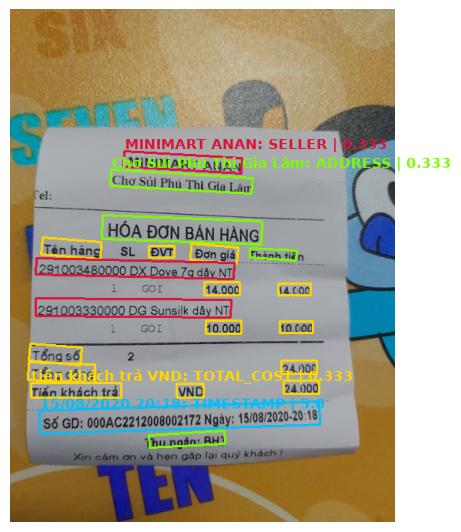

In [50]:
# Custom post-process
best_score_idx = find_highest_score_each_class1(preds, probs)
value_idx = find_total_cost_value(best_score_idx[3], boxes)
## --------DEBUG--------
# print(boxes)
# print(best_score_idx[3])
# print(value_idx)

if value_idx != best_score_idx[3]:
    texts[best_score_idx[3]] += (" " + texts[value_idx])

texts[best_score_idx[2]] = extract_timestamp(texts[best_score_idx[2]])
output_path = str(Path(OUTPUT_DIR) / img_id)
# Ensure the directory exists
try:
    os.makedirs(output_path, exist_ok=True)
    print(f"Directory {output_path} created successfully.")
except Exception as e:
    print(f"An error occurred while creating the directory: {e}")
# Visualize and save result
visualize(
    img2, boxes, texts, 
    img_name = f'{output_path}/result.jpg', 
    class_mapping=class_mapping, 
    labels = preds, probs = probs, 
    visualize_best=True)





# Create and write to the file
try:
    with open(os.path.join(output_path, 'result.txt'), 'w', encoding='utf-8') as f:
        for cls, idx in enumerate(best_score_idx):
            f.write(f"{idx_mapping[cls]} : {texts[idx]}\n")
    print("File written successfully.")
except Exception as e:
    print(f"An error occurred while writing to the file: {e}")
    

from PIL import Image  # Correct import
img = Image.open(f'{output_path}/result.jpg')
display(img)

## Metric assignment

- IQE: RMSE on original quality labels and predictions in [0, 1].
- KIE: standard CER can exceed 1; use explicitly labeled NCER for bounded [0, 1] error.
- Do not rescale monetary RMSE into an image-quality score.


The previous single-image TOTAL_COST RMSE cell is retired. Use the shared experiment cell below.


## IQE and three KIE pipelines

The three-pipeline comparison reports both standard CER and NCER. 
The standalone IQE cell evaluates all 1,155 quality-labeled images on an 80/20 split, 
uses equal-width OCR batches on CUDA when available, and saves checkpoints for resuming.

Curate the store dictionary (text,lbl; SELLER=0) independently of the test set.


The previous batch cell reported TOTAL_COST RMSE. Use the next experiment cell for IQE RMSE and KIE CER.


In [51]:
import sys
print(sys.version)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [52]:
print(sys.executable)

C:\Users\trinh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe


In [53]:
# Primary IQE evaluation on all quality-labeled images is in the IQE-only cell.
# Run after PAN, VietOCR, PhoBERT and data/model setup cells.
import math, re, shutil, tempfile, unicodedata
from pathlib import Path
from difflib import SequenceMatcher
import cv2, numpy as np, pandas as pd, torch
from PIL import Image, ImageOps
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

GPU_DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.cuda.set_device(0)
print("Inference device:", GPU_DEVICE)

def move_if_torch(owner, attr):
    module=getattr(owner, attr, None)
    if isinstance(module, torch.nn.Module):
        module.to(GPU_DEVICE)
        return True
    return False

move_if_torch(ocr_model.model, "model")
if hasattr(ocr_model.model, "config"):
    ocr_model.model.config["device"]=str(GPU_DEVICE)
bert_model=retrieval.bert
move_if_torch(bert_model, "model")
if hasattr(bert_model, "device"):
    bert_model.device=GPU_DEVICE
pan_owner=det_model.model
pan_gpu=False
for attr in ("model","net","module"):
    pan_gpu=move_if_torch(pan_owner,attr) or pan_gpu
print("PAN module moved:", pan_gpu)

FIELDS=("SELLER","ADDRESS","TIMESTAMP","TOTAL_COST")
LABEL_BY_ID={int(v):str(k) for k,v in class_mapping.items()}
rows_for_eval=[r for r in train_rows if r.get("anno_texts") and r.get("anno_labels")]
if not rows_for_eval:
    raise ValueError("No labeled rows in mcocr_train_df.csv")

def scale_variants(im):
    # Padding changes the text size after VietOCR normalizes crop height.
    out=[im.convert("RGB")]
    for ratio in (0.08,0.16):
        px=max(1,int(im.width*ratio)); py=max(1,int(im.height*ratio))
        out.append(ImageOps.expand(im.convert("RGB"),border=(px,py,px,py),fill="white"))
    return out

def ocr_with_conf(im):
    with torch.inference_mode():
        text,conf=ocr_model(im,return_prob=True)
    try: conf=float(np.asarray(conf,dtype=float).mean())
    except Exception: conf=0.0
    return str(text),conf

def classify(texts):
    if not texts: return [],[]
    with torch.inference_mode():
        labels,probs=bert_model(texts)
    # PhoBERT.__call__ already maps checkpoint class IDs to label strings.
    return [str(label) for label in labels],[float(p) for p in probs]

# Pipeline 2/3 deterministic rules.
timestamp_re=re.compile(r"\b(?:\d{1,2}[:.]\d{2}(?::\d{2})?|\d{1,2}[/-]\d{1,2}[/-]\d{2,4})\b")
total_re=re.compile(r"(?i)(tong|thanh toan|total|amount|grand total|phai tra|cong)")
def fold_ascii(text):
    return "".join(ch for ch in unicodedata.normalize("NFD",str(text))
                   if unicodedata.category(ch)!="Mn").casefold()
def add_rules(texts,labels):
    result=list(labels)
    for i,t in enumerate(texts):
        if timestamp_re.search(t): result[i]="TIMESTAMP"
        elif total_re.search(fold_ascii(t)) and re.search(r"\d",t): result[i]="TOTAL_COST"
    return result

# Existing custom-dictionary.csv schema: text,lbl; replace with curated store names as needed.
dictionary={}
dict_path=Path(HEURISTIC_DIR)/"custom-dictionary.csv"
if dict_path.is_file():
    ddf=pd.read_csv(dict_path,encoding="utf-8")
    if {"text","lbl"}.issubset(ddf.columns):
        dictionary={str(r.text).strip().casefold():str(r.lbl).strip()
                    for r in ddf.dropna(subset=["text","lbl"]).itertuples()}
def add_store_dict(texts,labels,threshold=0.86):
    fixed=list(texts); result=list(labels)
    for i,text in enumerate(texts):
        q=str(text).strip().casefold()
        if not q or not dictionary: continue
        match,score=max(((term,SequenceMatcher(None,q,term).ratio()) for term in dictionary),
                        key=lambda x:x[1])
        if score>=threshold:
            fixed[i]=match
            try: result[i]=LABEL_BY_ID[int(float(dictionary[match]))]
            except (ValueError,KeyError): pass
    return fixed,result

def norm(s): return " ".join(str(s).casefold().split())
def edit_distance(a,b):
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]+[0]*len(b)
        for j,cb in enumerate(b,1):
            cur[j]=min(cur[j-1]+1,prev[j]+1,prev[j-1]+(ca!=cb))
        prev=cur
    return prev[-1]

# Single PAN pass; OCR base and multi-scale variants share the same crops.
crop_root=Path(tempfile.mkdtemp(prefix="invoice_iqe_kie_",dir=CACHE_DIR))
records=[]; iqe_features=[]
try:
    for row in tqdm(rows_for_eval,desc="Detect, OCR, classify"):
        image_path=TRAIN_IMAGE_DIR/row["img_id"]
        if not image_path.is_file(): continue
        bgr=cv2.imread(str(image_path))
        if bgr is None: continue
        blur=float(cv2.Laplacian(cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),cv2.CV_64F).var())
        resized=cv2.resize(bgr,(500,500),interpolation=cv2.INTER_AREA)
        outdir=crop_root/Path(row["img_id"]).stem
        try:
            _,boxes,_=det_model.model.predict(resized,output_dir=str(outdir),crop_region=True)
            crops=sorted(outdir.glob("*.png"),key=lambda p:natural_keys(p.name))
        except Exception:
            crops=[]
        base_texts=[]; base_conf=[]; multi_texts=[]
        for path in crops:
            with Image.open(path) as im:
                im=im.convert("RGB")
                variants=[ocr_with_conf(v) for v in scale_variants(im)]
            base_texts.append(variants[0][0]); base_conf.append(variants[0][1])
            multi_texts.append(max(variants,key=lambda x:x[1])[0])
        base_labels,_=classify(base_texts)
        rule_labels=add_rules(base_texts,base_labels)
        multi_labels,_=classify(multi_texts)
        multi_labels=add_rules(multi_texts,multi_labels)
        dict_texts,dict_labels=add_store_dict(multi_texts,multi_labels)
        records.append({"row":row,"variants":{
            "Mainworkflow":(base_texts,base_labels),
            "Mainworkflow + Rule-based Algorithms":(base_texts,rule_labels),
            "Mainworkflow + Rules + Store Dictionary + Multi-scale OCR":(dict_texts,dict_labels)}})
        iqe_features.append({"img_id":row["img_id"],"blur_laplacian_var":blur,
            "ocr_confidence_mean":float(np.mean(base_conf)) if base_conf else 0.0,
            "anno_image_quality":float(row["anno_image_quality"])})
finally:
    shutil.rmtree(crop_root,ignore_errors=True)

# Compare KIE CER per field and pipeline on identical annotated images.
cer_rows=[]
for record in records:
    row=record["row"]; gt_text=str(row["anno_texts"]).split("|||")
    gt_label=str(row["anno_labels"]).split("|||")
    if len(gt_text)!=len(gt_label): continue
    truth={f:[] for f in FIELDS}
    for t,l in zip(gt_text,gt_label):
        if l in truth: truth[l].append(t)
    for name,(texts,labels) in record["variants"].items():
        pred={f:[] for f in FIELDS}
        for t,l in zip(texts,labels):
            if l in pred: pred[l].append(t)
        for field in FIELDS:
            ref=norm(" ".join(truth[field])); hyp=norm(" ".join(pred[field]))
            if ref:
                cer_rows.append({"img_id":row["img_id"],"pipeline":name,"field":field,
                    "edit_distance":edit_distance(ref,hyp),"gt_characters":len(ref),
                    "prediction_characters":len(hyp),"normalization_characters":max(len(ref),len(hyp))})
detail=pd.DataFrame(cer_rows); summaries=[]
if not detail.empty:
    for (name,field),g in detail.groupby(["pipeline","field"]):
        edits=int(g.edit_distance.sum()); chars=int(g.gt_characters.sum()); denom=int(g.normalization_characters.sum())
        summaries.append({"pipeline":name,"field":field,"images":len(g),
            "edit_distance_sum":edits,"ground_truth_characters":chars,
            "CER":edits/chars if chars else float("nan"),
            "NCER":edits/denom if denom else 0.0})
    for name,g in detail.groupby("pipeline"):
        edits=int(g.edit_distance.sum()); chars=int(g.gt_characters.sum()); denom=int(g.normalization_characters.sum())
        summaries.append({"pipeline":name,"field":"MICRO","images":g.img_id.nunique(),
            "edit_distance_sum":edits,"ground_truth_characters":chars,
            "CER":edits/chars if chars else float("nan"),
            "NCER":edits/denom if denom else 0.0})
cer_summary=pd.DataFrame(summaries)
out=Path(OUTPUT_DIR); out.mkdir(parents=True,exist_ok=True)
cer_summary.to_csv(out/"kie_three_pipelines_cer.csv",index=False,encoding="utf-8-sig")
detail.to_csv(out/"kie_three_pipelines_cer_details.csv",index=False,encoding="utf-8-sig")

# IQE regression: blur + OCR confidence predict anno_image_quality.
iqe=pd.DataFrame(iqe_features).dropna()
if len(iqe)<10:
    print("IQE RMSE unavailable: too few labeled images.")
else:
    cols=["blur_laplacian_var","ocr_confidence_mean"]
    Xtr,Xte,ytr,yte=train_test_split(iqe[cols],iqe.anno_image_quality,
        test_size=0.20,random_state=42)
    iqe_model=RandomForestRegressor(n_estimators=300,min_samples_leaf=3,
        random_state=42,n_jobs=-1)
    iqe_model.fit(Xtr,ytr)
    pred=np.clip(iqe_model.predict(Xte),0.0,1.0)
    rmse=math.sqrt(mean_squared_error(yte,pred))
    test=iqe.loc[Xte.index,["img_id","anno_image_quality"]].copy()
    test["predicted_image_quality"]=pred
    test.to_csv(out/"iqe_kie_subset_test_predictions.csv",index=False,encoding="utf-8-sig")
    pd.DataFrame([{"model":"RandomForestRegressor",
        "features":"Laplacian blur variance + mean VietOCR confidence",
        "split":"80/20 held-out, random_state=42","test_images":len(test),
        "RMSE":rmse}]).to_csv(out/"iqe_kie_subset_rmse_summary.csv",index=False,encoding="utf-8-sig")
    print(f"IQE held-out RMSE: {rmse:.6f} on {len(test)} images")
iqe.to_csv(out/"kie_three_pipelines_image_features.csv",index=False,encoding="utf-8-sig")
print("Images evaluated:",len(records))
print("Store dictionary entries loaded:",len(dictionary))
print("GPU selected:",GPU_DEVICE)
display(cer_summary)


Inference device: cuda:0
PAN module moved: True


Detect, OCR, classify:   0%|          | 0/1153 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (2,164 outputs left out)

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

IQE held-out RMSE: 0.136593 on 231 images
Images evaluated: 1153
Store dictionary entries loaded: 125
GPU selected: cuda:0


,pipeline,field,images,edit_distance_sum,ground_truth_characters,CER,NCER
0,Mainworkflow,ADDRESS,1077,58921,54595,1.079238,0.780121
1,Mainworkflow,SELLER,1071,40826,16557,2.465785,0.829999
2,Mainworkflow,TIMESTAMP,1088,26970,27729,0.972628,0.972347
3,Mainworkflow,TOTAL_COST,1081,86157,25462,3.383748,0.871082
4,Mainworkflow + Rule-based Algorithms,ADDRESS,1077,54551,54595,0.999194,0.769603
5,Mainworkflow + Rule-based Algorithms,SELLER,1071,40074,16557,2.420366,0.827684
6,Mainworkflow + Rule-based Algorithms,TIMESTAMP,1088,25994,27729,0.937430,0.799766
7,Mainworkflow + Rule-based Algorithms,TOTAL_COST,1081,80401,25462,3.157686,0.864797
8,Mainworkflow + Rules + Store Dictionary + Mult...,ADDRESS,1077,53153,54595,0.973587,0.778160
9,Mainworkflow + Rules + Store Dictionary + Mult...,SELLER,1071,39731,16557,2.399650,0.819348


### GPU notes

KIE multi-scale OCR runs crop-wise. The standalone IQE evaluation batches equal-width crops 
in FP32, uses CUDA when available, and checks confidence against single-crop inference. 
Random Forest fitting runs on CPU. IQE results use the same fixed train/test split for all feature variants.


Displayed 30 receipts; saved report figure to C:\Users\trinh\OneDrive\Desktop\archive (1)\Invoice_OCR_Report\figures\mcocr_30_invoices.jpg


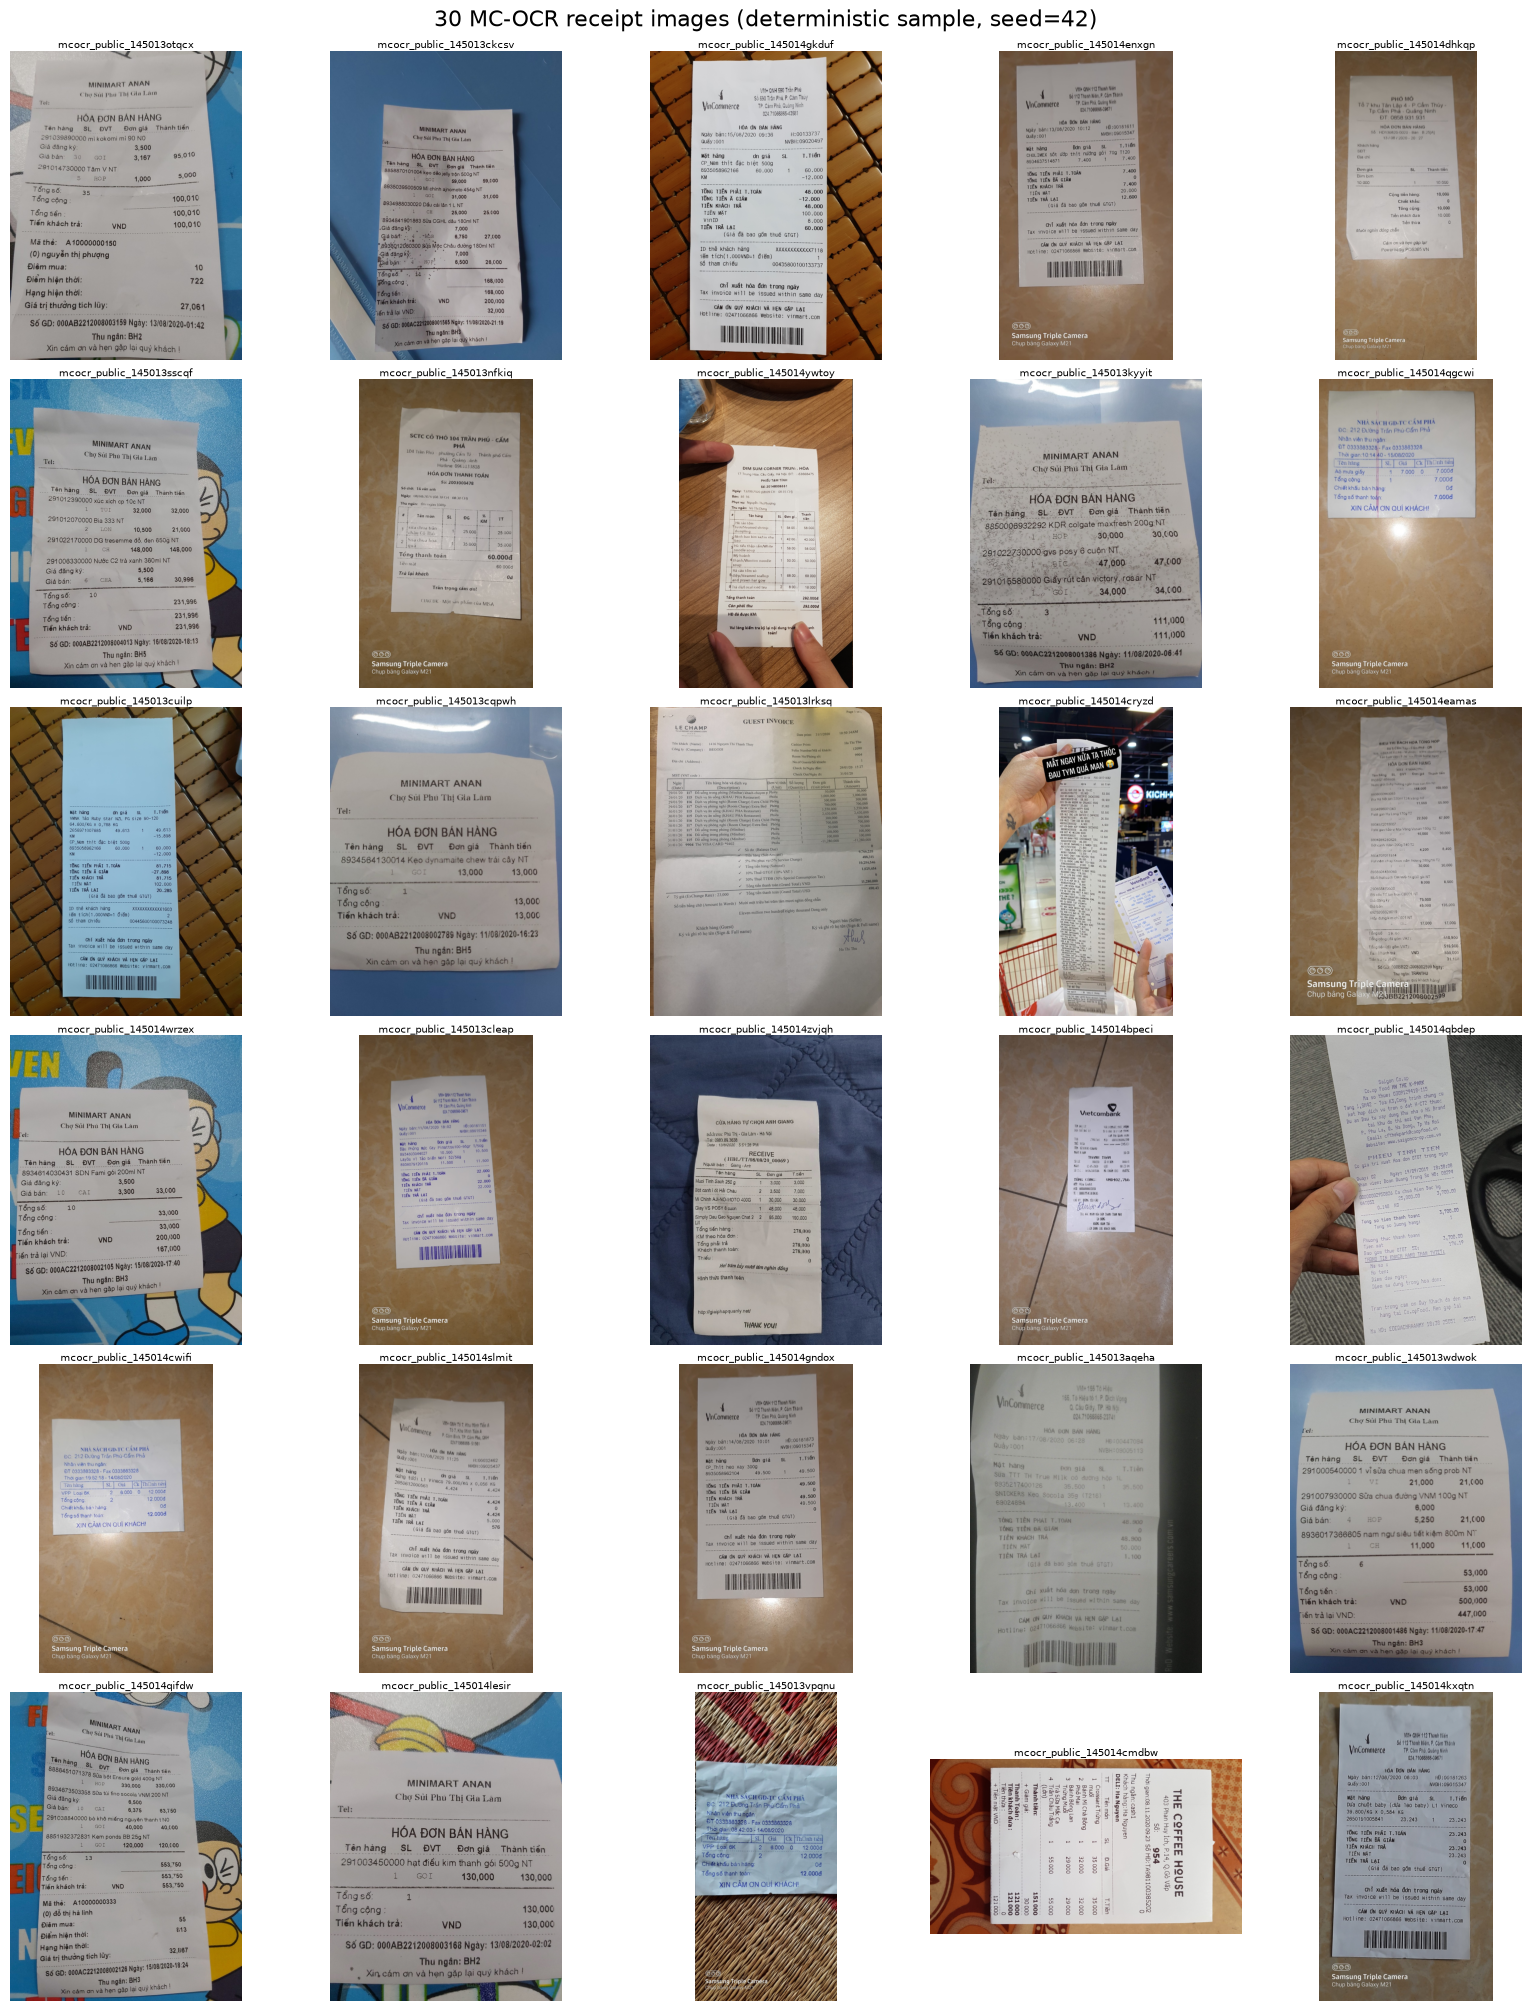

In [54]:
# Display a deterministic sample of 30 MC-OCR training receipts and save the report figure.
import random
from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
image_pool = sorted(
    p for p in TRAIN_IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
if len(image_pool) < 30:
    raise ValueError(f"Expected at least 30 images, found {len(image_pool)}")
selected_images = random.Random(42).sample(image_pool, 30)

fig, axes = plt.subplots(6, 5, figsize=(16, 20), constrained_layout=True)
for ax, image_path in zip(axes.flat, selected_images):
    with Image.open(image_path) as image:
        ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    ax.set_title(image_path.stem, fontsize=7, pad=2)
    ax.axis("off")
fig.suptitle("30 MC-OCR receipt images (deterministic sample, seed=42)", fontsize=16)
figure_dir = PROJECT_DIR / "Invoice_OCR_Report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "mcocr_30_invoices.jpg"
fig.savefig(figure_path, dpi=180, bbox_inches="tight", facecolor="white")
print(f"Displayed {len(selected_images)} receipts; saved report figure to {figure_path}")
plt.show()


In [55]:
# IQE on the original [0, 1] quality labels; independent of the KIE experiment.
# Run after data, PAN and VietOCR setup. Equal-width crops are batched on GPU.
import hashlib, json, math, time
from collections import defaultdict
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch
from PIL import Image
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

IQE_DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
IQE_BATCH_SIZE = 16
torch.set_num_threads(4)
cv2.setNumThreads(2)
predictor = ocr_model.model
predictor.model.to(IQE_DEVICE).eval()
predictor.config["device"] = str(IQE_DEVICE)
pan = det_model.model
pan.device = IQE_DEVICE
pan.net.to(IQE_DEVICE).eval()
print("IQE device:", IQE_DEVICE, "| OCR batch size:", IQE_BATCH_SIZE, flush=True)

def iqe_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

run_spec = {
    "version": "iqe-v2-equal-width-batch-fp32",
    "csv_sha256": iqe_sha256(TRAIN_CSV),
    "pan_sha256": iqe_sha256(WEIGHTS_DIR / "PANNet_best_map.pth"),
    "ocr_sha256": iqe_sha256(WEIGHTS_DIR / "transformerocr.pth"),
    "detection_input": [500, 500], "split_seed": 42,
}
run_key = hashlib.sha256(json.dumps(run_spec, sort_keys=True).encode()).hexdigest()[:16]
cache_root = Path(CACHE_DIR) / ("iqe_" + run_key)
cache_root.mkdir(parents=True, exist_ok=True)
manifest_path = cache_root / "detection_manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
out = Path(OUTPUT_DIR)
out.mkdir(parents=True, exist_ok=True)
start_time = time.time()

quality_rows = []
for row in train_rows:
    try:
        quality = float(row["anno_image_quality"])
    except (KeyError, TypeError, ValueError):
        continue
    if np.isfinite(quality):
        if not 0.0 <= quality <= 1.0:
            raise ValueError("Quality labels must already be in [0, 1].")
        quality_rows.append((row, quality))

for index, (row, quality) in enumerate(quality_rows, 1):
    image_id = row["img_id"]
    image_path = TRAIN_IMAGE_DIR / image_id
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    previous = manifest.get(image_id)
    if previous and all((cache_root / c).is_file() for c in previous["crops"]):
        continue
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise ValueError("Cannot read image: " + str(image_path))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    crops_dir = cache_root / Path(image_id).stem
    crops_dir.mkdir(exist_ok=True)
    resized = cv2.resize(bgr, (500, 500), interpolation=cv2.INTER_AREA)
    pan.predict(resized, output_dir=str(crops_dir), crop_region=True)
    crop_paths = sorted(crops_dir.glob("*.png"), key=lambda p: natural_keys(p.name))
    manifest[image_id] = {
        "blur_laplacian_var": blur, "anno_image_quality": quality,
        "crops": [p.relative_to(cache_root).as_posix() for p in crop_paths],
    }
    pending_manifest = manifest_path.with_suffix(".tmp")
    pending_manifest.write_text(json.dumps(manifest), encoding="utf-8")
    pending_manifest.replace(manifest_path)
    if index % 25 == 0 or index == len(quality_rows):
        print(f"PAN {index}/{len(quality_rows)} images; elapsed {time.time()-start_time:.1f}s", flush=True)

confidence_path = cache_root / "crop_confidences.jsonl"
confidences = {}
if confidence_path.exists():
    for line in confidence_path.read_text().splitlines():
        try:
            item = json.loads(line)
            confidences[item["crop"]] = float(item["confidence"])
        except (ValueError, KeyError):
            continue

dataset_cfg = predictor.config["dataset"]
groups = defaultdict(list)
for record in manifest.values():
    for crop in record["crops"]:
        if crop in confidences:
            continue
        with Image.open(cache_root / crop) as image:
            width = math.ceil(int(dataset_cfg["image_height"] * image.width / image.height) / 10) * 10
            width = max(width, dataset_cfg["image_min_width"])
            width = min(width, dataset_cfg["image_max_width"])
        groups[width].append(crop)

@torch.inference_mode()
def iqe_batch_confidence(crop_names):
    tensors = []
    for crop in crop_names:
        with Image.open(cache_root / crop) as image:
            tensors.append(process_input(
                image.convert("RGB"), dataset_cfg["image_height"],
                dataset_cfg["image_min_width"], dataset_cfg["image_max_width"],
            ))
    images = torch.cat(tensors).to(IQE_DEVICE)
    net = predictor.model
    memory = net.transformer.forward_encoder(net.cnn(images))
    count = len(crop_names)
    tokens = torch.ones((1, count), dtype=torch.long, device=IQE_DEVICE)
    finished = torch.zeros(count, dtype=torch.bool, device=IQE_DEVICE)
    totals = torch.zeros(count, device=IQE_DEVICE)
    lengths = torch.zeros(count, device=IQE_DEVICE)
    for _ in range(129):
        logits, memory = net.transformer.forward_decoder(tokens, memory)
        probabilities, ids = logits[:, -1, :].softmax(-1).max(-1)
        valid = (~finished) & (ids > 3)
        totals += probabilities * valid
        lengths += valid
        finished |= ids.eq(2)
        tokens = torch.cat((tokens, ids[None, :]), dim=0)
        if bool(finished.all()):
            break
    return (totals / lengths.clamp_min(1)).cpu().tolist()

total_pending = sum(len(items) for items in groups.values())
completed = 0
check_names = next((items[:2] for items in groups.values() if len(items) >= 2), [])
if check_names:
    reference = []
    for name in check_names:
        with Image.open(cache_root / name) as image:
            _, value = predictor.predict(image.convert("RGB"), return_prob=True)
        reference.append(float(value))
    batch_values = iqe_batch_confidence(check_names)
    difference = float(np.max(np.abs(np.asarray(reference) - np.asarray(batch_values))))
    if not np.isfinite(difference) or difference > 1e-4:
        raise ValueError("Batched confidence differs from single-crop inference: " + str(difference))
    run_spec["batch_check_max_abs_difference"] = difference
    print("Batch/single confidence max difference:", difference, flush=True)
print("OCR pending crops:", total_pending, "| cached:", len(confidences), flush=True)
with confidence_path.open("a", encoding="utf-8") as stream:
    for width, crop_names in sorted(groups.items()):
        for offset in range(0, len(crop_names), IQE_BATCH_SIZE):
            batch = crop_names[offset:offset + IQE_BATCH_SIZE]
            values = iqe_batch_confidence(batch)
            for crop, confidence in zip(batch, values):
                if not np.isfinite(confidence):
                    raise ValueError("Nonfinite OCR confidence: " + crop)
                confidences[crop] = confidence
                stream.write(json.dumps({"crop": crop, "confidence": confidence}) + "\n")
            stream.flush()
            completed += len(batch)
            if completed % 256 < IQE_BATCH_SIZE or completed == total_pending:
                print(f"OCR {completed}/{total_pending} crops; width {width}; elapsed {time.time()-start_time:.1f}s", flush=True)

feature_rows = []
for row, quality in quality_rows:
    record = manifest[row["img_id"]]
    values = [confidences[p] for p in record["crops"]]
    feature_rows.append({
        "img_id": row["img_id"], "blur_laplacian_var": record["blur_laplacian_var"],
        "ocr_confidence_mean": float(np.mean(values)) if values else 0.0,
        "anno_image_quality": quality, "ocr_regions": len(values),
    })
iqe_features_df = pd.DataFrame(feature_rows)
iqe_features_df.to_csv(out / "iqe_image_features.csv", index=False, encoding="utf-8-sig")
train_indices, test_indices = train_test_split(
    np.arange(len(iqe_features_df)), test_size=0.20, random_state=42,
)
y_train = iqe_features_df.iloc[train_indices].anno_image_quality
y_test = iqe_features_df.iloc[test_indices].anno_image_quality
test = iqe_features_df.iloc[test_indices][["img_id", "anno_image_quality"]].copy()
test = test.rename(columns={"anno_image_quality": "ground_truth_quality"})
summary_rows = []
variants = {
    "blur_only": ["blur_laplacian_var"],
    "confidence_only": ["ocr_confidence_mean"],
    "blur_and_confidence": ["blur_laplacian_var", "ocr_confidence_mean"],
}
for name, columns in variants.items():
    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
    model.fit(iqe_features_df.iloc[train_indices][columns], y_train)
    predictions = model.predict(iqe_features_df.iloc[test_indices][columns])
    if not np.isfinite(predictions).all() or not ((predictions >= 0) & (predictions <= 1)).all():
        raise ValueError("Predicted quality must be finite and in [0, 1].")
    rmse = math.sqrt(mean_squared_error(y_test, predictions))
    test["predicted_quality" if name == "blur_and_confidence" else name + "_quality"] = predictions
    summary_rows.append({
        "variant": name, "model": "RandomForestRegressor", "target_scale": "[0, 1]",
        "train_images": len(train_indices), "test_images": len(test_indices),
        "split_seed": 42, "RMSE": rmse, "features": " + ".join(columns),
    })
baseline = np.full(len(y_test), float(y_train.mean()))
summary_rows.append({
    "variant": "mean_train_baseline", "model": "TrainingMean", "target_scale": "[0, 1]",
    "train_images": len(train_indices), "test_images": len(test_indices),
    "split_seed": 42, "RMSE": math.sqrt(mean_squared_error(y_test, baseline)), "features": "none",
})
iqe_summary = pd.DataFrame(summary_rows)
iqe_summary.to_csv(out / "iqe_rmse_summary.csv", index=False, encoding="utf-8-sig")
test.to_csv(out / "iqe_rmse_test_predictions.csv", index=False, encoding="utf-8-sig")
run_spec.update({
    "device": str(IQE_DEVICE), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "torch": torch.__version__, "image_count": len(feature_rows),
    "ocr_regions": int(iqe_features_df.ocr_regions.sum()), "elapsed_seconds": time.time() - start_time,
    "test_images": test.img_id.tolist(), "quality_min": float(iqe_features_df.anno_image_quality.min()),
    "quality_max": float(iqe_features_df.anno_image_quality.max()),
})
(out / "iqe_run_metadata.json").write_text(json.dumps(run_spec, indent=2), encoding="utf-8")
print("IQE_RESULTS", iqe_summary.to_json(orient="records"), flush=True)
print(iqe_summary.to_string(index=False), flush=True)


IQE device: cuda:0 | OCR batch size: 16
OCR pending crops: 0 | cached: 17319
IQE_RESULTS [{"variant":"blur_only","model":"RandomForestRegressor","target_scale":"[0, 1]","train_images":924,"test_images":231,"split_seed":42,"RMSE":0.1472686593,"features":"blur_laplacian_var"},{"variant":"confidence_only","model":"RandomForestRegressor","target_scale":"[0, 1]","train_images":924,"test_images":231,"split_seed":42,"RMSE":0.1425720615,"features":"ocr_confidence_mean"},{"variant":"blur_and_confidence","model":"RandomForestRegressor","target_scale":"[0, 1]","train_images":924,"test_images":231,"split_seed":42,"RMSE":0.1274976664,"features":"blur_laplacian_var + ocr_confidence_mean"},{"variant":"mean_train_baseline","model":"TrainingMean","target_scale":"[0, 1]","train_images":924,"test_images":231,"split_seed":42,"RMSE":0.1346655278,"features":"none"}]
            variant                 model target_scale  train_images  test_images  split_seed     RMSE                                 features

In [56]:
# Standard CER is unbounded; NCER is the normalized edit error in [0, 1].
from pathlib import Path
import numpy as np
import pandas as pd

metric_dir = Path(OUTPUT_DIR)
kie_detail = pd.read_csv(metric_dir / "all_data_cer_details.csv", keep_default_na=False)
kie_detail["prediction_characters"] = kie_detail["prediction"].str.len()
kie_detail["normalization_characters"] = np.maximum(
    kie_detail["gt_characters"], kie_detail["prediction_characters"],
)
if not (kie_detail["ground_truth"].str.len() == kie_detail["gt_characters"]).all():
    raise ValueError("Reference strings do not match the stored character counts.")
if not (kie_detail["edit_distance"] <= kie_detail["normalization_characters"]).all():
    raise ValueError("Stored edit distances exceed the normalized Levenshtein bound.")
kie_detail["NCER"] = np.divide(
    kie_detail["edit_distance"], kie_detail["normalization_characters"],
    out=np.zeros(len(kie_detail), dtype=float),
    where=kie_detail["normalization_characters"].to_numpy() > 0,
)
normalized_rows = []
for field, group in list(kie_detail.groupby("field", sort=False)) + [("MICRO", kie_detail)]:
    edits = int(group.edit_distance.sum())
    normalization = int(group.normalization_characters.sum())
    normalized_rows.append({
        "field": field, "images": group.img_id.nunique(),
        "edit_distance_sum": edits, "normalization_characters": normalization,
        "NCER": edits / normalization if normalization else 0.0,
        "NCER_macro": float(group.NCER.mean()),
        "standard_CER": edits / int(group.gt_characters.sum()),
    })
normalized_kie = pd.DataFrame(normalized_rows)
normalized_kie.to_csv(metric_dir / "all_data_normalized_cer_by_field.csv", index=False, encoding="utf-8-sig")
kie_detail.to_csv(metric_dir / "all_data_normalized_cer_details.csv", index=False, encoding="utf-8-sig")
display(normalized_kie[["field", "images", "NCER"]].round({"NCER": 6}))

# Reload the completed IQE result without running OCR again.
if (metric_dir / "iqe_rmse_summary.csv").is_file():
    iqe_current_summary = pd.read_csv(metric_dir / "iqe_rmse_summary.csv")
    display(iqe_current_summary[["variant", "RMSE"]].round({"RMSE": 6}))


,field,images,NCER
0,SELLER,1071,0.829139
1,ADDRESS,1077,0.770332
2,TIMESTAMP,1088,0.808083
3,TOTAL_COST,1081,0.865043
4,MICRO,1153,0.823024


,variant,RMSE
0,blur_only,0.147269
1,confidence_only,0.142572
2,blur_and_confidence,0.127498
3,mean_train_baseline,0.134666
